# Project Background

**Project Overview**

This notebook implements an end-to-end solution for warehouse space optimisation and inbound volume forecasting. It clusters individual products by operational attributes, then applies time-series models to predict monthly inbound volumes for each cluster. Additionally, it analyses stakeholder feedback using sentiment analysis to identify and prioritise key warehouse inefficiencies.

**Objective & Scope**

Objective: Improve warehouse slotting and resource planning by grouping products with similar handling profiles and forecasting inbound shipment volumes. Additionally, to identify and quantify key warehouse inefficiencies based on stakeholder feedback to validate project objectives.

Scope:

- Perform clustering on key metrics (volume, weight, handling complexity, and storage cost).

- Forecast monthly volumes for each cluster using SARIMAX and Prophet.

- Analyse internal stakeholder feedback to validate operational priorities.

**Stakeholders**

- Warehouse Managers – Oversee picking efficiency and slotting.

- Operations Directors – Monitor KPIs and capacity.

- Supply Chain Planners – Use forecasts for resourcing.

- IT/Data Teams – Support model integration.

- Warehouse Staff – Provide feedback on real-world inefficiencies.

**Business Value**

- Space Utilisation: Allocate items in the correct location for more efficient operations.

- Operational Efficiency: Reduce picker travel time and congestion by aligning storage zones with pick frequency and volume profiles.

- Resource Planning: Use forecasts to optimise staffing, equipment scheduling, and inventory buffer levels.

- Improved Employee Satisfaction Address key points identified through feedback analysis, leading to a more positive working environment.

- Data-Driven Prioritisation: Use insights from sentiment analysis to prioritize which inefficiencies to address first.


**Data Source Identification**

- The datasets included in this repository are entirely synthetic and have been created solely for the purposes of learning, testing, and demonstrating forecasting and machine learning techniques. They should not be interpreted as real operational, financial, or commercial data.

# Perform sentiment analysis



In [1]:
import pandas as pd

def read_feedback_data(file_path: str) -> pd.DataFrame:
    """
    Reads warehouse feedback data from a CSV file.

    Steps
    ------
    - Reads the CSV file into a DataFrame.
    - Ensures the feedback column is string-typed.

    Parameters
    ----------
    file_path : str
        Path to the CSV file containing warehouse feedback.

    Returns
    -------
    pd.DataFrame
        DataFrame containing the feedback data.

    Example Usage
    -------------
    df = read_feedback_data('warehouse_feedback.csv')
    """
    df = pd.read_csv(file_path)
    if 'feedback' in df.columns:
        df['feedback'] = df['feedback'].astype(str)
    return df

## Perform sentiment analysis

Use VADER to analyse the sentiment of each feedback entry to quantify the positivity or negativity of the feedback.

In [2]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import pandas as pd

# Ensure VADER lexicon is available
try:
    nltk.data.find('sentiment/vader_lexicon.zip')
except LookupError:
    nltk.download('vader_lexicon')


def perform_sentiment_analysis(feedback_df: pd.DataFrame) -> pd.DataFrame:
    """
    Performs sentiment analysis on warehouse feedback using VADER.

    Steps
    ------
    - Initialises the VADER sentiment analyser.
    - Apply the analyser to each feedback entry.
    - Extract sentiment scores (negative, neutral, positive, compound).
    - Append these scores as new columns to the original DataFrame.

    Returns
    -------
    pd.DataFrame
        DataFrame with additional sentiment score columns.

    Example Usage
    -------------
    df = perform_sentiment_analysis(feedback_df)
    """
    try:
        analyzer = SentimentIntensityAnalyzer()
        sentiment_scores = feedback_df['feedback'].apply(lambda x: analyzer.polarity_scores(x))
        feedback_df['neg_sentiment'] = sentiment_scores.apply(lambda x: x['neg'])
        feedback_df['neu_sentiment'] = sentiment_scores.apply(lambda x: x['neu'])
        feedback_df['pos_sentiment'] = sentiment_scores.apply(lambda x: x['pos'])
        feedback_df['compound_sentiment'] = sentiment_scores.apply(lambda x: x['compound'])
        return feedback_df
    except Exception as e:
        print(f"Error during sentiment analysis: {e}")
        return feedback_df

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


## Categorise feedback

Categorise the feedback based on the type of inefficiency mentioned (e.g., picking, storage, delays).


In [3]:
def categorise_inefficiency(feedback: str) -> str:
    """
    Categorises feedback into warehouse inefficiency types based on keywords.

    Steps
    ------
    - Convert feedback to lowercase for consistent keyword matching.
    - Check for presence of keywords related to picking, storage, delays, damage, etc.
    - Return the corresponding inefficiency category.

    Returns
    -------
    str
        Inefficiency category label.

    Example Usage
    -------------
    category = categorise_inefficiency("Picking speed is too slow.")
    """
    feedback_lower = feedback.lower()
    try:
        if 'picking' in feedback_lower or 'picked' in feedback_lower or 'picker' in feedback_lower:
            if 'error' in feedback_lower or 'incorrect' in feedback_lower:
                return 'Picking Errors'
            elif any(word in feedback_lower for word in ['slow', 'speed', 'difficult', 'searching']):
                return 'Picking Efficiency Issues'
            else:
                return 'Picking Issues (General)'
        elif any(word in feedback_lower for word in ['storage', 'stored', 'racks', 'shelves', 'layout']):
            return 'Storage Issues'
        elif any(word in feedback_lower for word in ['delay', 'delayed', 'backlogs', 'queues', 'bottleneck']):
            return 'Delays'
        elif 'damage' in feedback_lower or 'damaged' in feedback_lower:
            return 'Damage'
        elif any(word in feedback_lower for word in ['forecast', 'volume', 'planning', 'shipments']):
            return 'Forecast Gaps'
        else:
            return 'Other Inefficiency'
    except Exception as e:
        print(f"Error categorising feedback: {e}")
        return 'Uncategorised'

## Analyse sentiment by category

Calculate the average sentiment score for each category of inefficiency to identify which areas are causing the most warehouse problem.

In [4]:
def apply_inefficiency_categorisation(df: pd.DataFrame) -> pd.DataFrame:
    """
    Applies inefficiency categorisation to a DataFrame of feedback.

    Steps
    ------
    - Apply the categorise_inefficiency function to each feedback entry.
    - Add a new column with the resulting category.

    Returns
    -------
    pd.DataFrame
        DataFrame with an added 'inefficiency_category' column.

    Example Usage
    -------------
    df = apply_inefficiency_categorisation(feedback_df)
    """
    try:
        df['inefficiency_category'] = df['feedback'].apply(categorise_inefficiency)
        return df
    except Exception as e:
        print(f"Error applying inefficiency categorisation: {e}")
        return df

In [5]:
def analyse_sentiment_by_category(df: pd.DataFrame) -> pd.Series:
    """
    Analyses average sentiment by inefficiency category.

    Steps
    ------
    - Groups feedback by inefficiency category
    - Calculates average compound sentiment score for each category
    - Sorts the results in ascending order

    Returns
    -------
    pd.Series
        Series of average sentiment scores by category.

    Example Usage
    -------------
    sentiment_summary = analyse_sentiment_by_category(df)
    """
    sentiment_by_category = df.groupby('inefficiency_category')['compound_sentiment'].mean()
    sentiment_by_category_sorted = sentiment_by_category.sort_values(ascending=True)
    return sentiment_by_category_sorted

# Preparation

## Step 1: Load and Explore the Dataset

In [6]:
!pip install prophet

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import itertools
from itertools import product
from prophet import Prophet
import matplotlib.pyplot as plt
import statsmodels.api as sm
from typing import Tuple
from typing import Dict
from typing import Dict, Optional, Any
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet.diagnostics import cross_validation, performance_metrics
from sklearn.model_selection import ParameterGrid

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("priced_inventory_data (3).csv")

In [8]:
def inspect_inventory_data(file_path: str) -> pd.DataFrame:
    """
    Loads and inspects the inventory dataset.

    Steps
    ------
    - Loads the CSV file into a DataFrame
    - Prints dataset structure using .info()
    - Prints summary statistics using .describe()

    Parameters
    ----------
    file_path : str
        Path to the CSV file containing inventory data.

    Returns
    -------
    pd.DataFrame
        The loaded DataFrame for further processing.

    Example Usage
    -------------
    df = inspect_inventory_data("priced_inventory_data (3).csv")
    """
    df = pd.read_csv(file_path)

    print("Dataset Info:")
    print(df.info())

    print("\nSummary Statistics:")
    print(df.describe())

    return df

## Step 2: Feature Engineering

In [9]:
def feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    """
    Performs feature engineering on the inventory dataset.

    Steps
    ------
    - Converts 'Received date' to datetime format
    - Imputes missing values using mean
    - Removes duplicate product_id entries
    - Displays quantiles (25%, 50%, 75%) for numerical columns
    - Creates new features:
        - est_monthly_revenue
        - rev_per_kg
        - storage_efficiency
        - volume_weight_ratio
        - is_premium
        - high_seasonality
        - category_popularity

    Returns
    -------
    pd.DataFrame
        Cleaned and enriched DataFrame with new features.

    Example Usage
    -------------
    df = pd.read_csv("priced_inventory_data (3).csv")
    df = feature_engineering(df)
    """

    df['Received date'] = pd.to_datetime(df['Received date'], dayfirst=True, errors='coerce')

    print("\nMissing values before imputation:")
    print(df.isnull().sum())

    for column in df.columns:
        if df[column].isnull().any():
            if df[column].dtype in ['int64', 'float64']:
                df[column].fillna(df[column].mean(), inplace=True)
            else:
                df[column].fillna(df[column].mode()[0], inplace=True)

    print("\nMissing values after imputation:")
    print(df.isnull().sum())

    print("\nNumber of duplicate product_ids before removal:", df.duplicated(subset=['product_id']).sum())
    df.drop_duplicates(subset=['product_id'], keep='first', inplace=True)
    print("Number of duplicate product_ids after removal:", df.duplicated(subset=['product_id']).sum())


    numerical_df = df.select_dtypes(include=np.number)
    print("\nQuantiles (25%, 50%, 75%):")
    print(numerical_df.quantile([0.25, 0.5, 0.75]))

    df['est_monthly_revenue'] = df['avg_volume'] * df['price']
    df['rev_per_kg'] = df['est_monthly_revenue'] / df['weight_kg'].replace(0, np.nan)
    df['storage_efficiency'] = df['avg_volume'] / df['storage_cost_per_unit'].replace(0, np.nan)
    df['volume_weight_ratio'] = df['avg_volume'] / df['weight_kg'].replace(0, np.nan)
    df['is_premium'] = (df['price'] > df['price'].median()).astype(int)
    df['high_seasonality'] = (df['seasonality'] > 1.1).astype(int)
    df['category_popularity'] = df.groupby('category')['avg_volume'].transform('mean')

    return df

## Step 3: Exploratory Data Analysis

In [10]:
def perform_full_eda(df: pd.DataFrame) -> None:
    """
    Performs full exploratory data analysis on the inventory dataset.

    Parameters
    ----------
    df : pd.DataFrame
        The inventory dataset with engineered features.

    Returns
    -------
    None
        Displays all plots.
    """
    sns.set(style="whitegrid")

    # Scatter plots
    # Estimated Monthly Revenue vs. Average Volume by Category
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=df, x='avg_volume', y='est_monthly_revenue', hue='category', s=100)
    plt.title('Estimated Monthly Revenue vs. Average Volume by Category')
    plt.xlabel('Average Volume')
    plt.ylabel('Estimated Monthly Revenue')
    plt.legend(title='Category')
    plt.grid(True)
    plt.show()

    # Estimated Monthly Revenue vs. Storage Cost per Unit by Category
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=df, x='storage_cost_per_unit', y='est_monthly_revenue', hue='category', s=100)
    plt.title('Estimated Monthly Revenue vs. Storage Cost per Unit')
    plt.xlabel('Storage Cost per Unit')
    plt.ylabel('Estimated Monthly Revenue')
    plt.legend(title='Category')
    plt.grid(True)
    plt.show()

    # Revenue per Kg vs. Storage Efficiency by Category
    plt.figure(figsize=(12, 7))
    plot_data = df.replace([np.inf, -np.inf], np.nan).dropna(subset=['rev_per_kg', 'storage_efficiency'])
    sns.scatterplot(data=plot_data, x='storage_efficiency', y='rev_per_kg', hue='category', s=100)
    plt.title('Revenue per Kg vs. Storage Efficiency by Category')
    plt.xlabel('Storage Efficiency')
    plt.ylabel('Revenue per Kg')
    plt.legend(title='Category')
    plt.grid(True)
    plt.show()

    # Pick Frequency vs. Lead Time Days by Category
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=df, x='lead_time_days', y='pick_frequency', hue='category', s=100)
    plt.title('Pick Frequency vs. Lead Time Days by Category')
    plt.xlabel('Lead Time Days')
    plt.ylabel('Pick Frequency')
    plt.legend(title='Category')
    plt.grid(True)
    plt.show()

    # Pick Frequency vs. Average Volume by Category
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=df, x='avg_volume', y='pick_frequency', hue='category', s=100)
    plt.title('Pick Frequency vs. Average Volume by Category')
    plt.xlabel('Average Volume')
    plt.ylabel('Pick Frequency')
    plt.legend(title='Category')
    plt.grid(True)
    plt.show()

    # Pairplot of Key Features by Category
    pairplot_features = ['est_monthly_revenue', 'avg_volume', 'price', 'weight_kg', 'storage_efficiency', 'category']
    sns.pairplot(df[pairplot_features].dropna(), hue='category', diag_kind='kde')
    plt.suptitle('Relationships of Key Features by Category', y=1.02)
    plt.show()

    # Log-transformed revenue
    df['log_est_monthly_revenue'] = np.log1p(df['est_monthly_revenue'])

    # Distribution of Estimated Monthly Revenue
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(df['est_monthly_revenue'].dropna(), bins=50, kde=True)
    plt.title("Distribution of Estimated Monthly Revenue")
    plt.xlabel("Estimated Monthly Revenue")
    plt.ylabel("Frequency")

    # Distribution of Log(Estimated Monthly Revenue + 1)
    plt.subplot(1, 2, 2)
    sns.histplot(df['log_est_monthly_revenue'].dropna(), bins=50, kde=True, color='orange')
    plt.title("Distribution of Log(Estimated Monthly Revenue + 1)")
    plt.xlabel("Log(Estimated Monthly Revenue + 1)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    # Average volume distribution
    plt.figure(figsize=(6, 4))
    sns.histplot(df['avg_volume'].dropna(), bins=50, kde=True)
    plt.title("Distribution of Average Volume")
    plt.xlabel("Average Volume")
    plt.ylabel("Frequency")
    plt.show()

    # Box Plot of Average Volume
    plt.figure(figsize=(6, 4))
    sns.boxplot(y=df['avg_volume'].dropna())
    plt.title("Box Plot of Average Volume")
    plt.ylabel("Average Volume")
    plt.show()

    # Distribution of Estimated Monthly Revenue by Category
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x='category', y='est_monthly_revenue')
    plt.title("Distribution of Estimated Monthly Revenue by Category")
    plt.xlabel("Category")
    plt.ylabel("Estimated Monthly Revenue")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Distribution of Estimated Monthly Revenue by Premium Status
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='is_premium', y='est_monthly_revenue')
    plt.title("Distribution of Estimated Monthly Revenue by Premium Status")
    plt.xlabel("Is Premium (0: No, 1: Yes)")
    plt.ylabel("Estimated Monthly Revenue")
    plt.xticks(ticks=[0, 1], labels=['Not Premium', 'Premium'])
    plt.show()

    # Distribution of Seasonality by Category
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x='category', y='seasonality')
    plt.title("Distribution of Seasonality by Category")
    plt.xlabel("Category")
    plt.ylabel("Seasonality Index")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Correlation heatmap of Key Numerical Features
    plt.figure(figsize=(10, 8))
    corr_features = ['est_monthly_revenue', 'avg_volume', 'price', 'weight_kg', 'storage_cost_per_unit', 'seasonality']
    sns.heatmap(df[corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Matrix of Key Numerical Features including Revenue')
    plt.show()

## Step 4: Encoding categorical data

In [11]:
def encode_categorical_features(df: pd.DataFrame, categorical_features: list) -> pd.DataFrame:
    """
    Applies one-hot encoding to specified categorical features.

    Steps
    ------
    - Selects the specified categorical features.
    - Applies one-hot encoding using 'pd.get_dummies'.
    - Removes the original categorical columns.
    - Returns the DataFrame with encoded features.

    Parameters
    ----------
    df : pd.DataFrame
        The input DataFrame containing categorical columns.
    categorical_features : list
        List of column names to encode.

    Returns
    -------
    pd.DataFrame
        DataFrame with one-hot encoded categorical features.
    """
    df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True)

    print("DataFrame after One-Hot Encoding:")
    display(df_encoded.head())

    print("\nData Types after Encoding:")
    print(df_encoded.dtypes)

    return df_encoded

## Step 5: OneHot Encoding categorical data

In [12]:
def convert_boolean_columns(df: pd.DataFrame) -> pd.DataFrame:
    """
    Converts boolean columns in the DataFrame to integer (0/1) format.

    Steps
    ------
    - Iterates through each column in the DataFrame.
    - Checks if the column's data type is boolean.
    - If boolean, converts the column to integer type (0 or 1).
    - Returns the DataFrame with boolean columns converted to integers.

    Parameters
    ----------
    df : pd.DataFrame
        The input DataFrame with potential boolean columns.

    Returns
    -------
    pd.DataFrame
        DataFrame with boolean columns converted to integers.
    """
    for col in df.columns:
        if df[col].dtype == 'bool':
            df[col] = df[col].astype(int)

    print("DataFrame after encoding:")
    display(df.head())

    print("\nData Types after encoding:")
    print(df.dtypes)

    return df

## Step 6: Outlier Winsorisation

Winsorisation limits extreme values in data. It replaces values below a low percentile (5%), and values above a high percentile (95%) with that percentile's value.

This reduces the impact of outliers in clustering, leading to more stable groupings.

In [13]:
def winsorise_outliers(df: pd.DataFrame, lower_quantile: float = 0.05, upper_quantile: float = 0.95) -> pd.DataFrame:
    """
    Caps numeric features at specified lower and upper quantiles to reduce the influence of outliers.

    Steps
    ------
    - Creates a copy of the input DataFrame.
    - Identifies and processes numerical columns.
    - Replaces values below the lower quantile and above the upper quantile with the quantile values.
    - Returns the DataFrame with winsorised numeric features.

    Parameters
    ----------
    df : pd.DataFrame
        The input DataFrame with numerical features.
    lower_quantile : float
        The lower quantile threshold (default is 0.05).
    upper_quantile : float
        The upper quantile threshold (default is 0.95).

    Returns
    -------
    pd.DataFrame
        A new DataFrame with winsorised numeric features.
    """
    df_win = df.copy()
    num_cols = df_win.select_dtypes(include=[np.number]).columns

    for col in num_cols:
        lower = df_win[col].quantile(lower_quantile)
        upper = df_win[col].quantile(upper_quantile)
        df_win[col] = df_win[col].clip(lower, upper)

    print("DataFrame after Winsorisation:")
    display(df_win.head())

    return df_win

 # Clustering

## Step 7: Clustering Preparation by Scaling Measures

Why use:

- K-Means: Efficiently groups items based on numerical attributes such as volume and pick frequency. Works well for large datasets due to speed and simplicity.

Benefits:

- Groups similar items for consistent storage/handling.
- Simplifies data-driven product placement.

- Ensures all numerical features contribute equally to K-Means by standardisisg their range. This is crucial as K-Means relies on measuring distances between data points.


In [14]:
def scale_numeric_features(df: pd.DataFrame) -> np.ndarray:
    """
    Scales numeric features using StandardScaler for clustering and analysis.

    Steps
    ------
    - Identifies numerical columns in the DataFrame.
    - Initialises a StandardScaler.
    - Fits the scaler to the numerical features and transforms them.
    - Returns the scaled feature matrix as a NumPy array.

    Parameters
    ----------
    df : pd.DataFrame
        The input DataFrame with numeric features.

    Returns
    -------
    np.ndarray
        Scaled numeric feature matrix.
    """
    num_cols = df.select_dtypes(include=[np.number]).columns
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df[num_cols])

    print("First 5 rows of scaled features:")
    display(X_scaled[:5])

    return X_scaled

## Step 8: Optimal k Detection

What it does:

Tests different numbers of clusters (*k*) to see which one works best by using:

- Inertia: Measures how tightly grouped the items are in each cluster.
- Silhouette Score: Measures how well each item fits in its cluster compared to others.


Why it's important:
- Helps pick the best number of clusters without making them too many (overfitting) or too few (underfitting).


In [15]:
def find_optimal_k(X_scaled: np.ndarray, k_range: range = range(2, 11)) -> Tuple[int, list, list]:
    """
    Determines the optimal number of clusters using the Elbow and Silhouette methods.

    Steps
    ------
    - Initialises empty lists for inertias and silhouette scores.
    - Iterates through the specified range of k values.
    - For each k, fits a KMeans model to the scaled data and predicts cluster labels.
    - Appends the inertia and silhouette score to their respective lists.
    - Plots the inertia and silhouette scores against k.
    - Determines the optimal k as the value with the highest silhouette score.
    - Returns the optimal k, the list of inertias, and the list of silhouette scores.

    Parameters
    ----------
    X_scaled : np.ndarray
        Scaled feature matrix for clustering.
    k_range : range, optional
        Range of k values to evaluate.

    Returns
    -------
    int
        The optimal number of clusters based on the highest silhouette score.
    list
        List of inertia values for each k.
    list
        List of silhouette scores for each k.
    """
    inertias = []
    silhouettes = []

    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        inertias.append(kmeans.inertia_)
        silhouettes.append(silhouette_score(X_scaled, labels))

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(k_range, inertias, 'o-')
    plt.title("Elbow Method")
    plt.xlabel("k")
    plt.ylabel("Inertia")

    plt.subplot(1, 2, 2)
    plt.plot(k_range, silhouettes, 'o-r')
    plt.title("Silhouette Score")
    plt.xlabel("k")
    plt.ylabel("Score")

    plt.tight_layout()
    plt.show()

    optimal_k = k_range[np.argmax(silhouettes)]
    print(f"Optimal number of clusters based on silhouette score: {optimal_k}")

    return optimal_k, inertias, silhouettes

## Step 9: Clustering

What it does:

- K-Means groups items into clusters based on how similar they are. Each cluster has a centroid (average point) in that group.

- To assign an item to a cluster, the model calculates the Euclidean distance—a straight-line distance—between the item and each centroid. The item is placed in the cluster with the nearest centroid.

Why it's important:

- Groups items with similar characteristics for efficient storage and planning.


In [16]:
def assign_clusters(df: pd.DataFrame, X_scaled: np.ndarray, n_clusters: int) -> pd.DataFrame:
    """
    Assigns KMeans cluster labels to the DataFrame and counts the number of items in each cluster.

    Steps
    ------
    - Creates a copy of the input DataFrame.
    - Initialises and fits a KMeans model to the scaled feature matrix, predicts cluster labels.
    - Adds a 'cluster' column with assigned labels, prints item count per cluster.
    - Returns the DataFrame with cluster assignments.

    Parameters
    ----------
    df : pd.DataFrame
        The original DataFrame to which cluster labels will be added.
    X_scaled : np.ndarray
        Scaled feature matrix used for clustering.
    n_clusters : int
        The number of clusters to form.

    Returns
    -------
    pd.DataFrame
        The DataFrame with an added 'cluster' column indicating cluster assignments.
    """
    df_clustered = df.copy()
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_clustered['cluster'] = kmeans.fit_predict(X_scaled)

    print("Cluster counts:")
    print(df_clustered['cluster'].value_counts())

    return df_clustered

## Step 10: Cluster Profiling & Naming


In [17]:
def calculate_cluster_means(df: pd.DataFrame, cluster_col: str = 'cluster') -> pd.DataFrame:
    """
    Groups the DataFrame by the cluster column and calculates the mean of all numerical features.

    Steps
    ------
    - Groups the input DataFrame by the specified cluster column.
    - Calculates the mean of all numerical features for each cluster.
    - Returns a DataFrame containing the mean values per cluster.

    Parameters
    ----------
    df : pd.DataFrame
        The clustered DataFrame containing a column with cluster labels.
    cluster_col : str
        The name of the column containing cluster labels.

    Returns
    -------
    pd.DataFrame
        A DataFrame containing the mean values of numerical features for each cluster.
    """
    cluster_means = df.groupby(cluster_col).mean(numeric_only=True)

    print("Mean values of features by cluster:")
    display(cluster_means)

    return cluster_means

Why This Step:

- To give each cluster a clear, descriptive name that reflects its operational characteristics.

Why it's important:

- These intuitive names help stakeholders quickly understand product groupings for better warehouse planning.

Output Analysis:

- Cluster 0 (Low-Value Chemicals): High pick frequency, low weight and price. Storage-efficient with high volume-to-weight ratio. Ideal for fast-moving inventory.

- Cluster 1 (High-Value Pharmaceuticals): Moderate pick frequency, high volume and price. High seasonality and storage efficiency. Premium items needing secure, prioritised storage.

- Cluster 2 (Mid-Value Electronics): Low pick frequency, high weight, moderate price. Strong seasonality and low storage efficiency. Requires flexible storage planning.






In [18]:
def rename_clusters(    cluster_means: pd.DataFrame,cluster_name_mapping: dict | None = None) -> tuple[pd.DataFrame, dict]:
    """
    Renames the index of the cluster means DataFrame using a mapping of cluster labels to descriptive names.

    Steps
    ------
    - Defines a default cluster name mapping if none is provided.
    - Checks if the cluster means index contains labels not present in the mapping and raises an error if so.
    - Renames the index of the cluster means DataFrame using the provided or default mapping.
    - Returns the DataFrame with the renamed index and the mapping used.

    Parameters
    ----------
    cluster_means : pd.DataFrame
        DataFrame with cluster labels as index and mean values of features.
    cluster_name_mapping : dict
        Dictionary mapping cluster labels (int) to descriptive names (str). If None, a default mapping is used.

    Returns
    -------
    tuple[pd.DataFrame, dict]
        A tuple containing:
        - pd.DataFrame: DataFrame with renamed index using descriptive cluster names.
        - dict: The cluster name mapping used.
    """
    if cluster_name_mapping is None:
        cluster_name_mapping = {
            0: "Low-Value Chemicals",
            1: "High-Value Pharmaceuticals",
            2: "Mid-Value Electronics",
        }

    missing = set(cluster_means.index) - set(cluster_name_mapping.keys())
    if missing:
        raise ValueError(f"Cluster name mapping missing entries for: {missing}")

    renamed = cluster_means.rename(index=cluster_name_mapping)
    print("Cluster means with descriptive names:")
    display(renamed)

    return renamed, cluster_name_mapping

## Block 11: PCA Visualisation of Clusters

What it does:

- Uses Principal Component Analysis (PCA) to reduce the scaled feature space to two dimensions.
- Plots each item in this 2D space, colored by cluster, with centroids marked.

Centroids Calculation:
- K-Means centroids are the average position (mean vector) of all items in each cluster.
- These centroids are transformed into the PCA space and shown as 'X' markers on the plot.
- This visual shows how clusters are separated and where their centers lie in the reduced space.


In [19]:
def plot_clusters_pca(X_scaled: np.ndarray, df: pd.DataFrame, kmeans: KMeans, cluster_col: str = 'cluster') -> pd.DataFrame:
    """
    Projects high-dimensional data into 2D PCA space and visualises KMeans clusters and centroids.

    Steps
    ------
    - Initialises a PCA model to reduce data to 2 components, fits and transforms the scaled feature matrix.
    - Creates a DataFrame with PCA components and cluster labels.
    - Define cluster colour for consistency with EDA visualisations.
    - Plots data points in 2D PCA space, coloured by cluster, and adds cluster centroids.
    - Displays the plot and returns the DataFrame with PCA components and labels.

    Parameters
    ----------
    X_scaled : np.ndarray
        Scaled feature matrix used for PCA projection.
    df : pd.DataFrame
        DataFrame containing cluster labels.
    kmeans : KMeans
        Trained KMeans model with cluster centres.
    cluster_col : str, optional
        Name of the column in df containing cluster labels (default is 'cluster').

    Returns
    -------
    pd.DataFrame
        DataFrame containing PCA components and cluster labels.
    """
    pca = PCA(n_components=2)
    proj = pca.fit_transform(X_scaled)

    pca_df = pd.DataFrame(proj, columns=['PC1', 'PC2'], index=df.index)
    pca_df[cluster_col] = df[cluster_col]

    color_map = {
        0: sns.color_palette()[0],
        1: sns.color_palette()[2],
        2: sns.color_palette()[1]
    }

    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue=cluster_col, palette=color_map, s=60)

    centroids_2d = pca.transform(kmeans.cluster_centers_)
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=200, c='black', label='Centroids')

    plt.title('K-Means Clusters (PCA)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return pca_df

## Step 12: Cluster-Based Recommendations

In [20]:
def summarise_clusters(
    df: pd.DataFrame,
    cluster_name_mapping: Dict[int, str],
    cluster_col: str = 'cluster'
) -> None:
    """
    Prints a summary of each cluster with descriptive statistics and storage recommendations.

    Steps
    ------
    - Iterates through each unique cluster ID in the DataFrame.
    - Skips cluster -1 (typically for noise or unassigned points).
    - Filters the DataFrame to get data for the current cluster.
    - Retrieves the descriptive name for the cluster using the mapping.
    - Prints summary statistics for the cluster, including product count, average volume, price, etc.
    - Prints a storage recommendation based on the cluster's characteristics, using the cluster name mapping.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing cluster labels and relevant numeric features.
    cluster_name_mapping : dict
        Dictionary mapping cluster numbers to descriptive names.
    cluster_col : str, optional
        Name of the column containing cluster labels (default is 'cluster').
    """
    for c in sorted(df[cluster_col].unique()):
        if c == -1:
            print("\nSkipping cluster -1 (items with missing data).")
            continue

        data_c = df[df[cluster_col] == c].copy()
        cluster_display_name = cluster_name_mapping.get(c, f'Cluster {c} (Unknown Name)')

        print(f"\nCluster {c} ({cluster_display_name}):")
        print(f"  Products: {len(data_c)}")
        print(f"  Average Volume: {data_c['avg_volume'].mean():.1f}")
        print(f"  Average Price: £{data_c['price'].mean():.2f}")
        print(f"  Volume CV: {data_c['volume_cv'].mean():.2f}")

        storage_efficiency_mean = data_c['storage_efficiency'].replace([np.inf, -np.inf], np.nan).mean()
        print(f"  Storage Efficiency: {storage_efficiency_mean:.2f}")
        print(f"  Average Weight: {data_c['weight_kg'].mean():.2f} kg")
        print(f"  Average Pick Frequency: {data_c['pick_frequency'].mean():.1f}")
        print(f"  Average Lead Time: {data_c['lead_time_days'].mean():.1f} days")

        if c in cluster_name_mapping:
            if cluster_name_mapping[c] == "Low-Value Chemicals":
                print("  Recommendation: Store in high-access zones near picking/packing. Focus on efficient flow due to high pick frequency and low handling cost.")
            elif cluster_name_mapping[c] == "Mid-Value Electronics":
                 print("  Recommendation: Store in bulk or less accessible areas due to lower pick frequency and higher weight. Manage space efficiently for these items with longer lead times.")
            elif cluster_name_mapping[c] == "High-Value Pharmaceuticals":
                 print("  Recommendation: Store in moderately accessible, secure zones that can handle higher volumes. Balance security for high-price items with reasonable access for moderate pick frequency.")
            else:
                 print("  Recommendation: No specific recommendation available for this cluster.")


# Forecasting SARIMAX


Why Use:

- SARIMAX is chosen for forecasting monthly inbound volumes because it models trends and seasonal patterns present in the data.
- Uses SARIMAX to forecast future monthly volumes for each cluster.
- Captures trend and seasonality.

Why it's important:

- Supports inventory planning and resource allocation at cluster level.

- Accounts for seasonal variation common in warehouse operations.




## Step 13: Forecasting Data Preparation

What it does:

- Prepares monthly total volume time series for each cluster.

- Groups by cluster, resamples to month-end (ME), and sums the value column into monthly_volume.

Sets Received date as the time index.

Why it's important:

- Structures data for time-series models to capture cluster-specific trends and seasonality.

In [21]:
def prepare_time_series_by_cluster(df: pd.DataFrame, date_col: str = 'Received date', cluster_col: str = 'cluster',
                                   value_col: str = 'avg_volume') -> pd.Series:
    """
    Prepares a time series of monthly volume per cluster.

    Steps
    ------
    - Selects relevant columns and sets date as index.
    - Groups by cluster and resamples to monthly frequency.
    - Calculates the sum of the value column for each month.
    - Returns the multi-indexed time series.

    Parameters
    ----------
    df : pd.DataFrame
        The input DataFrame containing date, cluster, and volume information.
    date_col : str
        Name of the column containing date values.
    cluster_col : str
        Name of the column containing cluster labels.
    value_col : str
        Name of the column containing volume values.

    Returns
    -------
    pd.Series
        A time series indexed by cluster and month, showing total monthly volume.
    """
    df_ts = df[[date_col, cluster_col, value_col]].copy()
    df_ts = df_ts.set_index(date_col)

    ts = (df_ts.groupby(cluster_col)[value_col]
          .resample('ME')
          .sum()
          .rename('monthly_volume'))

    print("Monthly volume per cluster:")
    display(ts.head())
    print("Index type:", ts.index.dtype)
    print("Sample index values:", ts.index[:5])

    return ts

## Step 14: Stationarity Check (ADF)

What it does:

-  Checks whether each cluster’s monthly volume data is stationary — meaning its statistical properties (like mean and variance) remain constant over time.

Why it's important:
- SARIMAX (like ARIMA) works best when the data is stationary. If the data isn’t stable, the model’s forecasts can become unreliable. This test helps make sure the data is ready for accurate forecasting.
- While the ADF test may indicate non-stationarity, SARIMAX models can handle this through differencing (the 'I' component), making them suitable for such data.



In [22]:
def test_stationarity_by_cluster(ts: pd.Series) -> None:
    """
    Performs the Augmented Dickey-Fuller (ADF) test on each cluster's monthly volume series
    to assess stationarity.

    Steps
    ------
    - Identifies the unique cluster IDs from the time series index.
    - Iterates through each cluster ID.
    - Selects the time series data for the current cluster.
    - Performs the Augmented Dickey-Fuller test on the cluster's time series (dropping NaNs if any).
    - Prints the ADF statistic, p-value, and critical values.
    - Prints a conclusion based on the p-value (stationary if p-value <= 0.05).

    Parameters
    ----------
    ts : pd.Series
        A multi-indexed time series with 'cluster' and datetime index, containing monthly volumes.

    Returns
    -------
    None
        Prints the ADF p-value and conclusion for each cluster.
    """
    clusters = sorted(ts.index.get_level_values('cluster').unique())

    for c in clusters:
        series = ts.loc[c]
        pval = adfuller(series.dropna())[1]
        conclusion = 'Stationary (reject H₀)' if pval <= 0.05 else 'Non-Stationary (fail to reject H₀)'
        print(f"Cluster {c} ADF p-value: {pval:.4f} → {conclusion}")

## Step 15: Time Series Decomposition

What it does:

- Breaks each cluster’s monthly volume into trend, seasonal, and residual components using an additive model.

Why it’s important:

- Helps visualise long-term patterns and recurring cycles, confirming seasonality and supporting seasonal models like SARIMAX.

Output Analysis:

- Cluster 0: Lower volume, weak trend, noisy residuals. Seasonality is irregular. Still suitable for SARIMAX if differencing stabilises the series.

- luster 1: Clear trend and strong, repeatable seasonality. Well suited to SARIMAX.

- Cluster 2: Visible trend and noticeable seasonality; residuals show some irregularity. Also suitable for SARIMAX.


In [23]:
def decompose_cluster_time_series(ts: pd.Series, cluster_col: str = 'cluster') -> None:
    """
    Decomposes and visualises the seasonal components of a monthly volume time series for each cluster.

    Steps
    ------
    - Identifies unique cluster IDs from the time series index.
    - Iterates through each cluster, selects its time series, and ensures frequency is set.
    - Performs seasonal decomposition using the additive model.
    - Plots and displays decomposition components: observed, trend, seasonal, and residual.


    Parameters
    ----------
    ts : pd.Series
        A multi-indexed time series with 'cluster' and datetime index, containing monthly volumes.
    cluster_col : str, optional
        The name of the cluster level in the index (default is 'cluster').

    Returns
    -------
    None
        Displays decomposition plots for each cluster.
    """
    clusters = sorted(ts.index.get_level_values(cluster_col).unique())

    for c in clusters:
        series = ts.loc[c]
        series.index.freq = series.index.inferred_freq
        decomposition = seasonal_decompose(series, model='additive')
        fig = decomposition.plot()
        fig.suptitle(f"Cluster {c} Decomposition", y=1.02)
        plt.tight_layout()
        plt.show()

## Step 16: ACF & PACF





What it does:

- ACF (Autocorrelation Function): Correlation between the current value and past values at different lags.

- PACF (Partial Autocorrelation Function): Direct relationship with a specific lag after removing intermediate effects.

Why it’s important:

- Helps choose SARIMAX structure:

  - AR terms (how many past months to include),

  - Differencing (I terms) to stabilise the series,

  - Seasonal AR/MA terms if seasonal patterns are present.

Output Analysis:

- Lag 1: Strong correlation across all clusters (current volume is strongly related to last month’s).

- Lag 12: Clear seasonal spike in Cluster 1, confirming annual seasonality.

- Clusters 0 and 2: No significant autocorrelation at lag 12; volumes are driven more by recent months than by same month last year.




In [24]:
def plot_acf_pacf_by_cluster(ts: pd.Series, lags: int = 12, cluster_col: str = 'cluster') -> None:
    """
    Plots the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF)
    for each cluster's monthly volume time series.

    Steps
    ------
    - Identifies the unique cluster IDs from the time series index.
    - Iterates through each cluster ID.
    - Selects the time series data for the current cluster.
    - Generates and displays the ACF plot for the current cluster's series up to the specified lags.
    - Generates and displays the PACF plot for the current cluster's series up to the specified lags.

    Parameters
    ----------
    ts : pd.Series
        A multi-indexed time series with 'cluster' and datetime index, containing monthly volumes.
    lags : int
        Number of lags to include in the ACF and PACF plots.
    cluster_col : str
        The name of the cluster level in the index.

    Returns
    -------
    None
        Displays ACF and PACF plots for each cluster.
    """
    clusters = sorted(ts.index.get_level_values(cluster_col).unique())

    for c in clusters:
        series = ts.loc[c]
        plot_acf(series, lags=lags)
        plt.title(f"ACF – Cluster {c}")
        plt.tight_layout()
        plt.show()

        plot_pacf(series, lags=lags)
        plt.title(f"PACF – Cluster {c}")
        plt.tight_layout()
        plt.show()

## Step 17: Train/Test Split

What it does:

- Each cluster’s monthly volume data is split into:
- Training data: January 2020 to December 2023
- Testing data: January 2024 to December 2024
- This structure is applied consistently across all clusters.

Why it's important:

- Using a fixed 12-month test period allows to:
  - Compare model performance across clusters
  - Evaluate how well each model handles recent unseen data

In [25]:
def split_cluster_time_series(ts: pd.Series, min_months: int = 24, test_size: int = 12) -> Tuple[Dict[int, pd.Series], Dict[int, pd.Series]]:
    """
    Splits each cluster's monthly time series into training and test sets.

    Steps
    ------
    - Initialises empty dictionaries for training and test series per cluster.
    - Iterates through each unique cluster ID, selects and sorts its time series.
    - Checks if the series meets the minimum required months; if valid, splits into training and test sets.
    - Stores each set in its respective dictionary, prints size and date range.
    - Returns the training and test dictionaries.

    Parameters
    ----------
    ts : pd.Series
        A multi-indexed time series with 'cluster' and datetime index, containing monthly volumes.
    min_months : int
        Minimum number of months required to perform a split.
    test_size : int
        Number of months to allocate to the test set.

    Returns
    -------
    Tuple[Dict[int, pd.Series], Dict[int, pd.Series]]
        Two dictionaries containing training and test series for each cluster.
    """
    ts_cluster = {}
    ts_train = {}
    ts_test = {}

    for c in sorted(ts.index.get_level_values('cluster').unique()):
        series = ts.loc[c].sort_index()
        ts_cluster[c] = series

        if len(series) < min_months:
            print(f" Skipping Cluster {c} – only {len(series)} months of data")
            continue

        ts_train[c] = series.iloc[:-test_size]
        ts_test[c] = series.iloc[-test_size:]

        print(f" Cluster {c}:")
        print(f"   Training set: {len(ts_train[c])} months "
              f"({ts_train[c].index.min().strftime('%Y-%m')} to {ts_train[c].index.max().strftime('%Y-%m')})")
        print(f"   Test set:     {len(ts_test[c])} months "
              f"({ts_test[c].index.min().strftime('%Y-%m')} to {ts_test[c].index.max().strftime('%Y-%m')})")
        print("-" * 40)

    return ts_train, ts_test

## Step 18: Find Optimal Parameters

What it does:

- Performs a grid search over different combinations of SARIMAX parameters:

  - Non-seasonal: (p, d, q)

  - Seasonal: (P, D, Q, 12)

- Splits the training data for each cluster into an inner-training set and a validation set.

- Fits models on the inner-training set and selects the combination with the lowest Mean Absolute Error (MAE) on the validation set.

Why it’s important:

- Helps select the best model parameters for each cluster to improve forecast accuracy on future data while avoiding overfitting.

In [26]:
def tune_sarimax_per_cluster(ts_train: Dict[int, pd.Series],seasonal_period: int = 12) -> Dict[int, Dict[str, object]]:

    """
    Performs grid search to find the best SARIMAX hyperparameters for each cluster's time series
    using an internal validation split from the training data.

    For each cluster:
    - Splits the training series into an inner-training segment and a validation segment.
    - Fits SARIMAX models on the inner-training segment across a parameter grid.
    - Evaluates mean absolute error (MAE) on the validation segment.
    - Selects and stores the parameters with the lowest validation MAE.

    Parameters
    ----------
    ts_train : dict
        Dictionary mapping cluster IDs to their training time series
    seasonal_period : int, optional
        Seasonal period for SARIMAX.

    Returns
    -------
    dict
        Mapping of cluster IDs to a dictionary containing:
        - 'order': best (p, d, q)
        - 'seasonal_order': best (P, D, Q, s)
        - 'mae': validation MAE for the selected parameters
    """
    p = d = q = range(0, 2)
    P = D = Q = range(0, 2)
    s = seasonal_period

    best_params: Dict[int, Dict[str, object]] = {}

    for c, series in ts_train.items():
        y = pd.Series(series).dropna()

        val_h = int(max(1, min(s, np.ceil(len(y) * 0.1))))
        if len(y) <= val_h + 3:
            val_h = max(1, min(val_h, len(y) // 3))

        y_train_inner = y.iloc[:-val_h]
        y_val_inner = y.iloc[-val_h:]

        best_mae = float("inf")
        best_order = None
        best_seasonal_order = None

        for order in product(p, d, q):
            for seasonal in product(P, D, Q):
                seasonal_order = (seasonal[0], seasonal[1], seasonal[2], s)
                try:
                    model = SARIMAX(
                        y_train_inner,
                        order=order,
                        seasonal_order=seasonal_order,
                        enforce_stationarity=False,
                        enforce_invertibility=False
                    )
                    fit_res = model.fit(disp=False)

                    pred = fit_res.get_forecast(steps=val_h).predicted_mean
                    mae = mean_absolute_error(y_val_inner, pred)

                    if mae < best_mae:
                        best_mae = mae
                        best_order = order
                        best_seasonal_order = seasonal_order

                except Exception:
                    continue

        best_params[c] = {
            'order': best_order,
            'seasonal_order': best_seasonal_order,
            'mae': best_mae if np.isfinite(best_mae) else None
        }

        print(f"Cluster {c} → Best MAE: {best_mae:.4f}")
        print(f"Best order: {best_order}, Seasonal: {best_seasonal_order}")

    return best_params


## Step 19: Train SARIMAX Models

What it does:
- Fits a SARIMAX model to each cluster’s training data using the optimal parameters identified during hyperparameter tuning.

Why it's important:
- This step enables the model to learn from historical patterns in the data, preparing it to make accurate forecasts even when the data shows some fluctuations over time.



In [27]:
def retrain_and_forecast_sarimax(ts_train: Dict[int, pd.Series], best_params: Dict[int, Dict[str, object]],
                                 n_steps_forecast: int = 12) -> Tuple[Dict[int, object], Dict[int, pd.Series]]:
    """
    Retrains SARIMAX models using the best parameters for each cluster and forecasts the test set.

    Steps
    ------
    - Initialises empty dictionaries to store final fitted models and forecasts.
    - Iterates through each cluster with tuned parameters, prints training start message.
    - Initialises and fit a SARIMAX model using training data.
    - Initialises and fits SARIMAX model using training data, stores in 'final_models'.
    - Generates forecast for upcoming periods, stores in 'cluster_forecasts'.
    - Prints completion message and returns models and forecasts.


    Parameters
    ----------
    ts_train : dict
        Dictionary of training time series per cluster.
    best_params : dict
        Dictionary containing best SARIMAX parameters and MAE per cluster.
    n_steps_forecast : int
        Number of months to forecast (default is 12).

    Returns
    -------
    Tuple[Dict[int, object], Dict[int, pd.Series]]
        A tuple containing:
        - final_models: Fitted SARIMAX models per cluster.
        - cluster_forecasts: Forecasted values per cluster.
    """
    final_models = {}
    cluster_forecasts = {}

    for c in sorted(best_params.keys()):
        print(f"\nTraining final SARIMAX model for Cluster {c}...")

        model = SARIMAX(
            ts_train[c],
            order=best_params[c]['order'],
            seasonal_order=best_params[c]['seasonal_order'],
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        final_models[c] = model.fit(disp=False)
        forecast = final_models[c].get_forecast(steps=n_steps_forecast).predicted_mean

        cluster_forecasts[c] = forecast

        print(f"Forecast completed for Cluster {c}")

    return final_models, cluster_forecasts

## Step 20: Residual Diagnostic

What it does:

- Checks the residuals (errors) from the trained models to see if they are random and normally distributed, using plots and the Ljung–Box statistical test.

- A random pattern means the errors are scattered and unpredictable, which is ideal, as it shows the model has done a good job.

Why it's important:

- Confirms whether the model has captured all meaningful patterns in the data and whether its assumptions are met.

- Random residuals indicate a well-fitting mode

Output Analysis:

- Cluster 0: Ljung–Box p-value (lag=12) = 0.996 → residuals appear random. The model adequately captures the patterns for this cluster.

- Cluster 1: Ljung–Box p-value (lag=12) = 0.642 → residuals appear random. The model fit is appropriate for this cluster.

- Cluster 2: Ljung–Box p-value (lag=12) = 0.729 → residuals appear random. The model provides a good fit for this cluster.


In [28]:
def analyse_residuals(final_models: Dict[int, object]) -> None:
    """
    Performs residual diagnostics for each fitted SARIMAX model per cluster.

    Steps
    ------
    - Iterates through each fitted SARIMAX model in the input dictionary.
    - For each model, checks availability and prints a diagnostics header.
    - Extracts residuals, drops NaNs, and creates a figure with three subplots: residuals over time, ACF, and Q-Q plot.
    - Displays the figure and performs the Ljung-Box test for autocorrelation.
    - Prints p-value and conclusion on residual randomness.
    - Handles errors and prints a separator line.
    - Skips clusters with no available model.


    Parameters
    ----------
    final_models : dict
        Dictionary of fitted SARIMAX models per cluster.

    Returns
    -------
    None
        Displays residual plots and Ljung-Box test results for each cluster.
    """
    for c, fitted_model in final_models.items():
        if fitted_model:
            print(f"\nResidual Diagnostics for Cluster {c}:")
            try:
                resid = fitted_model.resid.dropna()

                fig, axs = plt.subplots(1, 3, figsize=(15, 5))

                # Residuals over time
                axs[0].plot(resid)
                axs[0].set_title(f'Cluster {c} Residuals Over Time')
                axs[0].set_xlabel('Date')
                axs[0].set_ylabel('Residual')

                # ACF of residuals
                plot_acf(resid, ax=axs[1], lags=12)
                axs[1].set_title(f'ACF of Residuals – Cluster {c}')

                # Q-Q plot for normality
                sm.qqplot(resid, line='s', ax=axs[2])
                axs[2].set_title(f'Q-Q Plot – Cluster {c}')

                plt.tight_layout()
                plt.show()

                # Ljung-Box test
                lb_result = acorr_ljungbox(resid, lags=[12], return_df=True)
                lb_p = lb_result['lb_pvalue'].iloc[0]

                print(f"  Ljung-Box p-value (lag=12): {lb_p:.3f}")
                if lb_p > 0.05:
                    print("  Residuals appear random.")
                else:
                    print("  Residuals show autocorrelation – model may need refinement.")

            except Exception as e:
                print(f"  Error with diagnostics for Cluster {c}: {e}")

            print("-" * 40)
        else:
            print(f"Skipping Cluster {c} — no model available.")
            print("-" * 40)

## Step 21: Make Predictions on Test Data

What it does:

- Generates 12-month forecasts (January to December 2024) for each cluster using the trained SARIMAX models and their best-fit parameters.

Why it's important:

- Forecasting on this unseen test period is crucial for evaluating the model's real-world performance and ensuring it can accurately predict future inbound volumes.





In [29]:
def generate_cluster_forecasts(final_models: Dict[int, Any], ts_test: Dict[int, pd.Series]) -> Dict[int, pd.Series]:
    """
    Generates forecast predictions for the test period using trained SARIMAX models.

    Steps
    ------
    - Initialises an empty dictionary to store cluster forecasts.
    - Iterates through each cluster in the test data, prints forecast generation message.
    - Checks for a fitted model in final_models; if available, determines forecast steps.
    - Generates forecast using get_forecast, aligns index with actual test data.
    - Stores aligned forecast in cluster_forecasts, prints completion message and date range.
    - Displays first 5 rows of the forecast, handles any exceptions.
    - Returns the dictionary of forecasted values for the test period per cluster.

    Parameters
    ----------
    final_models : dict
        Dictionary of fitted SARIMAX models for each cluster.
    ts_test : dict
        Dictionary of actual test time series per cluster.

    Returns
    -------
    dict
        Dictionary of forecasted values for the test period per cluster.
    """
    cluster_forecasts = {}

    for c in sorted(ts_test.keys()):
        print(f"Generating forecasts for Cluster {c}...")
        try:
            n_steps = len(ts_test[c])
            if c not in final_models or final_models[c] is None:
                print(f" Skipping Cluster {c}: No fitted model available.")
                print("-" * 30)
                continue

            fc = final_models[c].get_forecast(steps=n_steps).predicted_mean

            fc.index = ts_test[c].index
            cluster_forecasts[c] = fc

            start = fc.index.min().strftime('%Y-%m')
            end   = fc.index.max().strftime('%Y-%m')
            print(f"Forecast generated for Cluster {c} from {start} to {end}.")
            print("-" * 30)

            print(f"\nCluster {c} Forecasts (first 5 rows):")
            print(fc.head(), "\n")

        except Exception as e:
            print(f" Forecast failed for Cluster {c}: {e}")
            print("-" * 30)

    return cluster_forecasts

## Step 22: Comparing Actual vs Predicted values

What it does:

- Plots training, actual test, and forecast series together.

Why it's important:

- Provides a way to compare the performance of the model across different clusters and identify areas where forecasting accuracy needs improvement.

Output Analysis:

- Cluster 0: The forecast appears as a relatively straight line on the test data, indicating it did not capture the fluctuations or trend in the actual volumes for this period.

- Cluster 1: Forecasts generally follow the main trend and seasonal shape, but there are visible differences from actuals in specific months, indicating some missed short-term variability.

- Cluster 2: Forecasts follow the general trend but show larger gaps; some monthly variation is under/over-estimated.

Conclusion:

- The plots indicate that while SARIMAX captures broader patterns for some clusters, it struggles with the variability and specific trend for Cluster 0 on the test data. Evaluate model performance on test data will validate these visual observations with the quantitative metrics.

In [30]:
def plot_actual_vs_predicted(actuals: Dict[int, pd.Series],predictions: Dict[int, pd.Series]) -> None:
    """
    Plots actual vs predicted monthly volume for each cluster.

    Steps
    ------
    - Iterates through each cluster present in the predictions dictionary.
    - Retrieves the actual and predicted time series for the current cluster.
    - Creates a new figure for plotting.
    - Plots the actual values against their index.
    - Plots the predicted values against their index.
    - Sets the title, labels, and legend for the plot.
    - Displays the plot for the current cluster.

    Parameters
    ----------
    actuals : dict
        Dictionary of actual time series per cluster.
    predictions : dict
        Dictionary of predicted time series per cluster.

    Returns
    -------
    None
        Displays line plots comparing actual and predicted values.
    """

    for c in sorted(predictions.keys()):
        actual = actuals[c]
        predicted = predictions[c]

        plt.figure(figsize=(10, 5))
        plt.plot(actual.index, actual.values, label='Actual', marker='o')
        plt.plot(predicted.index, predicted.values, label='Predicted', marker='x')
        plt.title(f'Cluster {c} – Actual vs Predicted Monthly Volume')
        plt.xlabel('Date')
        plt.ylabel('Volume')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

## Step 23: Evaluate Model Performance on Test Data

What it does:

- Calculates MAE, RMSE, and MAPE for each cluster’s forecasts.

Why it's important:

- These numbers show how close the forecasts were to the actual values:
MAE and RMSE measure the size of the errors.
- MAPE shows the error as a percentage — useful for comparing across clusters.

Output Analysis:

- Cluster 0: While the forecast visually appeared as a straight line, missing fluctuations in actual volumes, the MAE was 9.75% of the test mean, indicating moderate accuracy over the test period.

- Cluster 1: The forecast captured the overall trend and seasonal shape well, with some short-term deviations. The MAE was 4.48% of the test mean, reflecting strong performance and a good fit for this cluster's patterns.

- Cluster 2: The forecast followed the general trend but showed noticeable gaps in certain months. The MAE was 4.49% of the test mean, demonstrating reliable forecasting for this cluster.

Conclusion:

- All clusters achieved MAPE below 15%, confirming the project hypothesis. SARIMAX performed reliably across cluster types. Prophet will be evaluated next to identify the optimal forecasting model.



In [31]:
def evaluate_forecast_accuracy(ts_test: Dict[int, pd.Series],cluster_forecasts: Dict[int, pd.Series]) -> Dict[int, Dict[str, float]]:
    """
    Evaluates forecast accuracy for each cluster using MAE, RMSE, and MAPE.

    Steps
    ------
    - Initialises empty dictionary to store evaluation results.
    - Iterates through each cluster for which forecasts are available.
    - Retrieves actual and predicted time series for the current cluster.
    - Aligns actual and predicted data.
    - Calculates evaluation metrics (MAE, RMSE, MAPE, Test Mean, MAE %).
    - Stores the calculated metrics in the results dictionary.
    - Prints evaluation results for each cluster.
    - Returns the dictionary containing the evaluation results per cluster.

    Parameters
    ----------
    ts_test : dict
        Dictionary of actual test time series per cluster.
    cluster_forecasts : dict
        Dictionary of predicted time series per cluster.

    Returns
    -------
    dict
        Dictionary containing evaluation metrics per cluster.
    """
    evaluation_results = {}

    for c in sorted(cluster_forecasts.keys()):
        actual = ts_test[c]
        predicted = cluster_forecasts[c]


        actual_aligned, predicted_aligned = actual.align(predicted, join='inner')

        if actual_aligned.empty:
             evaluation_results[c] = {'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan, 'Test_Mean': np.nan, 'MAE_%': np.nan}
             print(f"\n Cluster {c} Evaluation: No data for evaluation after alignment.")
             continue

        mae = mean_absolute_error(actual_aligned, predicted_aligned)
        rmse = np.sqrt(mean_squared_error(actual_aligned, predicted_aligned))

        mape_series = np.abs((actual_aligned - predicted_aligned) / actual_aligned.replace(0, np.nan))
        mape = mape_series.dropna().mean() * 100 if not mape_series.dropna().empty else np.nan

        test_mean = actual_aligned.mean()
        mae_percent = (mae / test_mean) * 100 if test_mean != 0 else np.nan

        evaluation_results[c] = {
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape,
            'Test_Mean': test_mean,
            'MAE_%': mae_percent
        }

        print(f"\n Cluster {c} Evaluation:")
        print(f"  MAE:  {evaluation_results[c]['MAE']:.2f}")
        print(f"  RMSE: {evaluation_results[c]['RMSE']:.2f}")
        print(f"  MAPE: {evaluation_results[c]['MAPE']:.2f}%")
        print(f"  MAE as % of Test Mean: {evaluation_results[c]['MAE_%']:.2f}%")

    return evaluation_results

## Step 24:  Visualise Forecasts on Test Data

What it does:

- Plots the training, actual test, and forecast series together for each cluster.

Why it’s important:

- Gives a visual check of how well the model follows the real pattern, seasonality, and trend—by seeing how close the forecast line is to the actual line.

Output Analysis:

- Cluster 0: The forecast starts to drift away from the actual data around mid-2024, missing several ups and downs. While earlier results showed moderate accuracy (MAE 9.75%), the recent forecast looks less reliable.

- Cluster 1: The forecast stays closer to the actual values than the other clusters, with smaller differences. This matches the strong MAE (4.48%) and confirms it has the best overall fit.

- Cluster 2: The forecast shows bigger and more frequent gaps from the actual data, especially after mid-2024. This supports the earlier finding that Cluster 2 had the weakest fit, even though its MAE (4.49%) was relatively low.

Conclusion:

- Forecast accuracy varies across clusters. Cluster 1 fits the actual data best. Cluster 0 captures the overall trend but misses some month-to-month changes. Cluster 2 shows the biggest differences from actuals. Further improvements should focus on Cluster 2, then Cluster 0, to boost overall performance.

In [32]:
def visualise_forecasts_on_test_data(ts_train: Dict[int, pd.Series],ts_test: Dict[int, pd.Series], cluster_forecasts: Dict[int, pd.Series]) -> None:
    """
    Visualises training data, actual test data, and SARIMAX forecasts for each cluster.

    Steps
    ------
    - Iterates through each cluster with training data.
    - Checks if test data and forecasts are available.
    - Retrieves train, actual test, and forecast series.
    - Plots data.
    - Skips if data is missing.

    Parameters
    ----------
    ts_train : dict
        Dictionary of training time series per cluster.
    ts_test : dict
        Dictionary of actual test time series per cluster.
    cluster_forecasts : dict
        Dictionary of forecasted time series per cluster.

    Returns
    -------
    None
        Displays line plots for each cluster.
    """
    for c in sorted(ts_train.keys()):
        if c in ts_test and c in cluster_forecasts and cluster_forecasts[c] is not None:
            train_series = ts_train[c]
            test_series = ts_test[c]
            forecast_series = cluster_forecasts[c]

            if not isinstance(forecast_series, pd.Series):
                print(f"Skipping Cluster {c} - forecast data is not in expected Series format.")
                continue

            plt.figure(figsize=(14, 6))

            plt.plot(train_series.index, train_series, label='Training Data', color='orange')

            plt.plot(test_series.index, test_series, label='Actual Test Data', color='blue')

            plt.plot(forecast_series.index, forecast_series, label='Forecast', color='green', linestyle='--')

            plt.title(f'Forecast vs. Actuals for Cluster {c}')
            plt.xlabel('Date')
            plt.ylabel('Monthly Volume')
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()
        else:
            print(f"Skipping Cluster {c} – missing test data or forecast.")

# Forecasting with Prophet

Why Use:

- Prophet models trend and seasonality with minimal tuning. It handles missing data and changepoints, and can include holiday effects when a calendar is provided.

Benefits:

- Fast fitting; clear decomposition into trend/seasonality/holidays.

Target Results:

- Side-by-side performance vs SARIMAX; clear seasonality/trend insights per cluster.

Business Value:

- Provides an alternative forecast and validation, improving confidence with transparent, interpretable results.

## Step 25:  Prepare Data for Prophet

What It Does:

- The data for each cluster is reshaped into two columns: one for dates (ds) and one for values (y), using monthly data. This format is required by Prophet to run forecasts.


Why It’s Important:
- Prophet requires a specific input format to function correctly. Without this structure, the model cannot interpret the time series.
-  Using a monthly frequency aligns the forecasts with typical business planning cycles, making the outputs more actionable for operational decision-making.



In [33]:
def prepare_prophet_data(ts: pd.Series, cluster_col: str = 'cluster') -> Dict[int, pd.DataFrame]:
    """
    Prepares time series data for Prophet modelling for each cluster.

    Steps
    ------
    - Initialises an empty dictionary to store Prophet-ready DataFrames.
    - Iterates through each unique cluster ID, prints preparation message.
    - Selects the time series, resets index, and renames columns to 'ds' and 'y'.
    - Converts 'ds' to datetime, sets as index, resamples to monthly frequency, and forward-fills missing dates.
    - Resets index again and stores the prepared DataFrame in prophet_data.
    - Displays the head of the DataFrame and returns the dictionary.

    Parameters
    ----------
    ts : pd.Series
        Multi-indexed time series with 'cluster' and datetime index, containing monthly volumes.
    cluster_col : str
        Name of the cluster level in the index (default is 'cluster').

    Returns
    -------
    dict
        Dictionary of Prophet-ready DataFrames per cluster.
    """
    prophet_data = {}

    for c in sorted(ts.index.get_level_values(cluster_col).unique()):
        print(f"Preparing Prophet data for Cluster {c}.")

        series = ts.loc[c]

        df_p = series.reset_index().rename(columns={'Received date': 'ds', 'monthly_volume': 'y'})
        df_p['ds'] = pd.to_datetime(df_p['ds'])
        df_p = df_p.set_index('ds').asfreq('M').ffill().reset_index()

        prophet_data[c] = df_p
        display(df_p.head())

    return prophet_data

## Step 26: Train Prophet models

What It Does:

- Trains a Prophet model for each cluster using its training time series. The model learns the historical patterns, including trend and seasonality, to make future predictions.

Why It’s Important:

- Fitting the model to the training data allows it to capture the unique characteristics of each cluster's volume history, which is essential for generating accurate forecasts.

In [34]:
def train_prophet_models(ts_train: Dict[int, pd.Series]) -> Dict[int, Prophet]:
    """
    Trains a Prophet model for each cluster using its training time series.

    Steps
    ------
    - Initialises empty dictionary for trained Prophet models.
    - Iterates through clusters and training series, prints training message.
    - Prepares data using helper function, skips if empty.
    - Fits Prophet model and stores in dictionary.
    - Prints completion message and returns trained models.

    Parameters
    ----------
    ts_train : dict
        Dictionary of training time series per cluster.

    Returns
    -------
    dict
        Dictionary of trained Prophet models per cluster.
    """
    prophet_models = {}

    for c, series in ts_train.items():
        print(f"Training Prophet model for Cluster {c} on training data...")

        df_p_train = series.reset_index().rename(columns={'Received date': 'ds', 'monthly_volume': 'y'})
        df_p_train['ds'] = pd.to_datetime(df_p_train['ds'])

        if df_p_train.empty:
            print(f"Skipping Cluster {c}: Training data is empty.")
            continue

        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.fit(df_p_train)
        prophet_models[c] = m
        print(f"→ Done for Cluster {c}")

    return prophet_models

##  Step 27: Generate and Visualise Prophet Forecasts

What it does:

- Generates and visualises baseline Prophet forecasts (training, actual test, and forecast).
- Visualises decomposed components (trend, seasonality).

Why It's Important:

- Visually assesses how well the baseline Prophet captures patterns and forecasts align with actual test data before tuning.
- Helps understand main time series drivers per cluster.


Output Analysis:

- Cluster 0: Prophet shows a weak trend and some seasonality. It captures the general direction but struggles with irregular spikes.

- Cluster 1: Captures the strong upward trend and seasonal peaks well. It follows the general flow but can miss irregular spikes.

- Cluster 2: Identifies the overall trend but smooths over sharper volume changes. It underestimates variability in these items.

Conclusion:

- Prophet provides a strong baseline for Cluster 1, which exhibits regular patterns. For Clusters 0 and 2, where data is more variable, further tuning or alternative models may be required to improve forecast accuracy.



In [35]:
def generate_and_visualise_prophet_forecasts(prophet_models: Dict[int, Prophet],ts_train: Dict[int, pd.Series],
                                             ts_test: Dict[int, pd.Series]) -> Tuple[Dict[int, pd.DataFrame], Dict[int, pd.Series]]:
    """
    Generates forecasts using trained Prophet models for each cluster and plots results.

    Steps
    ------
    - Initialises empty dictionaries for future dataframes and Prophet forecasts.
    - Iterates through trained Prophet models.
    - Prints forecasting message.
    - Generates forecast.
    - Stores forecast.
    - Plots forecast with actuals.
    - Plots components.
    - Prints separator.
    - Returns dictionaries of future dataframes and Prophet forecasts.

    Parameters
    ----------
    prophet_models : dict
        Dictionary of trained Prophet models per cluster.
    ts_train : dict
        Dictionary of training time series per cluster.
    ts_test : dict
        Dictionary of actual test time series per cluster.

    Returns
    -------
    tuple
        Tuple containing:
        - Dictionary of future dataframes per cluster.
        - Dictionary of forecasted values for the test period per cluster.
    """
    prophet_futures = {}
    prophet_forecasts = {}

    for c, m in prophet_models.items():
        print(f"Forecasting for Cluster {c}...")

        periods = len(ts_test[c])
        future = m.make_future_dataframe(periods=periods, freq='M')
        prophet_futures[c] = future

        # Generate forecast
        fcst = m.predict(future)

        # Save forecast for the test period
        prophet_forecasts[c] = fcst.set_index('ds')['yhat'].loc[ts_test[c].index]

        # Show forecast tail
        print("Forecast tail:")
        display(fcst[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

        # Plot forecast with actuals
        plt.figure(figsize=(14, 6))
        plt.plot(ts_train[c].index, ts_train[c].values, label='Training Data', color='orange')
        plt.plot(ts_test[c].index, ts_test[c].values, label='Actual Test Data', color='blue')
        plt.plot(fcst['ds'], fcst['yhat'], label='Prophet Forecast', color='green', linestyle='--')

        plt.title(f'Baseline Prophet Forecast vs. Actuals for Cluster {c}')
        plt.xlabel('Date')
        plt.ylabel('Monthly Volume')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        # Plot components (specific to Prophet)
        fig2 = m.plot_components(fcst)
        fig2.suptitle(f'Components – Cluster {c}', y=1.02)
        plt.tight_layout()
        plt.show()

        print("-" * 50)

    return prophet_futures, prophet_forecasts

## Step 28: Evaluate Prophet Forecast Accuracy

What It Does:

- Evaluates the accuracy of the baseline Prophet forecast for each cluster using MAE, RMSE, and MAPE on the test period.

Why It’s Important:

- Quantifies how well Prophet predicts unseen data.
- Lower values indicate better accuracy.
- Establishes a baseline before tuning and comparison.


- Cluster 0: Moderate accuracy (MAPE = 5.0%). Captures trend and seasonality but misses irregular spikes and short-term fluctuations.

- Cluster 1: Strongest performance (MAPE = 2.4%). Forecasts align closely with actuals, making it reliable for planning.

- Cluster 2: Limited accuracy (MAPE = 6.8%). Oversmooths variability and misses sharper changes in monthly volumes.

Conclusion:

- Prophet provides a solid baseline, especially for regular patterns (Cluster 1). In variable clusters (0 and 2), it captures general trends but struggles with short-term fluctuations. Further tuning or complementary models may improve accuracy.




In [36]:
def evaluate_prophet_forecasts(ts_test: Dict[int, pd.Series], prophet_forecasts: Dict[int, pd.Series]) -> Dict[int, Dict[str, float]]:
    """
    Evaluates Prophet forecasts for each cluster using standard error metrics.

    Steps
    ------
    - Initialises an empty dictionary to store evaluation metrics.
    - Iterates through each cluster for which forecasts are available.
    - Retrieves actual and predicted time series for the current cluster.
    - Aligns actual and predicted data.
    - Calculates evaluation metrics (MAE, RMSE, MAPE).
    - Stores the calculated metrics in the results dictionary.
    - Prints evaluation results for each cluster.
    - Returns the dictionary containing the evaluation results per cluster.

    Parameters
    ----------
    ts_test : dict
        Dictionary of actual test time series per cluster.
    prophet_forecasts : dict
        Dictionary of forecasted values per cluster from Prophet.

    Returns
    -------
    dict
        Dictionary containing MAE, RMSE, and MAPE for each cluster.
    """
    prophet_metrics = {}

    for c in sorted(ts_test.keys()):
        if c not in prophet_forecasts:
             continue

        actual = ts_test[c]
        pred = prophet_forecasts[c].loc[actual.index]

        mae = mean_absolute_error(actual, pred)
        rmse = np.sqrt(mean_squared_error(actual, pred))
        mape = (np.abs((actual - pred) / actual.replace(0, np.nan))).dropna().mean() * 100

        prophet_metrics[c] = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

        print(f"Cluster {c} → Prophet MAE={mae:.2f}, RMSE={rmse:.2f}, MAPE={mape:.1f}%")


    return prophet_metrics

## Step 29: Prophet Parameter Tuning

What it does:

- This step tests different model settings to see which ones work best. It checks how flexible the trend should be and how seasonality is handled. The model is trained and tested on different parts of the training data, and the best settings are chosen based on the lowest forecast error (MAPE).

Why it's important:

- Selecting the best-fitting parameters through cross-validation on the training data helps ensure the model captures each cluster’s volume behaviour more accurately on unseen data.





In [37]:
def tune_prophet_parameters(ts_train: Dict[int, pd.Series],param_grid: Dict[str, list],min_months_for_cv: int = 24,n_forecasts: int = 12,
                            period_months: int = 6) -> Dict[int, Optional[Dict[str, Any]]]:
    """
    Tunes Prophet hyperparameters for each cluster using cross-validation and selects the best configuration based on MAPE.

    Steps
    ------
    - Initialise dictionary for best parameters; iterate clusters, print tuning message, prepare Prophet data.
    - Skip if data insufficient; else calculate CV window, print settings, initialise best MAPE and parameters.
    - Iterate parameter combinations: fit models, perform cross-validation, calculate mean MAPE, update best if improved.
    - Store results per cluster, print best MAPE or failure message, and return dictionary of best parameters.

    Parameters
    ----------
    ts_train : dict
        Dictionary of training time series per cluster.
    param_grid : dict
        Dictionary specifying the grid of hyperparameters to test.
    min_months_for_cv : int
        Minimum number of months required for cross-validation (default is 24).
    n_forecasts : int
        Number of periods (months) to forecast (default is 12).
    period_months : int
        Period between cross-validation folds in months (default is 6).

    Returns
    -------
    dict
        Dictionary of best hyperparameters per cluster, or None if tuning was not possible.
    """
    best_prophet_params = {}

    for c, series in ts_train.items():
        print(f"\nTuning Cluster {c}...")

        df_p_train = series.reset_index()
        df_p_train.columns = ['ds', 'y']
        df_p_train['ds'] = pd.to_datetime(df_p_train['ds'])

        if len(df_p_train) < min_months_for_cv:
            print(f"  Skipping: Not enough data ({len(df_p_train)} months). Need at least {min_months_for_cv} months for cross-validation.")
            best_prophet_params[c] = None
            continue

        horizon_days = n_forecasts * 30
        period_days = period_months * 30
        total_train_days = len(df_p_train) * 30
        min_initial_days = min_months_for_cv * 30
        initial_window_days = max(min_initial_days, total_train_days - horizon_days - period_days - period_days)


        if initial_window_days < min_initial_days or initial_window_days + horizon_days + period_days > total_train_days:
            print(f"  Skipping Cluster {c}: Cannot find valid cross-validation window with {horizon_days}-day horizon and {period_days}-day period for {len(df_p_train)} months of data.")
            best_prophet_params[c] = None
            continue


        initial_window = f"{initial_window_days} days"
        period = f"{period_days} days"
        horizon = f"{horizon_days} days"

        print(f"  Using CV settings: initial={initial_window}, period={period}, horizon={horizon}")


        best_mape = float('inf')
        best_params = None

        for params in ParameterGrid(param_grid):
            model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, **params)

            try:
                model.fit(df_p_train)
                df_cv = cross_validation(model, initial=initial_window, period=period, horizon=horizon)

                if not df_cv.empty:
                    mape = performance_metrics(df_cv, metrics=['mape'])['mape'].mean()
                    if mape < best_mape:
                        best_mape = mape
                        best_params = params

            except Exception:
                continue

        if best_params:
            best_prophet_params[c] = best_params
            print(f"→ Best MAPE for Cluster {c}: {best_mape:.2%} | Params: {best_params}")
        else:
            print(f"→ No valid model found for Cluster {c}.")

    return best_prophet_params

## Step 30: Generate and Visualise Prophet Forecasts (tuned)

What it does:

- Trains and forecasts with Prophet using tuned parameters.
- Visualises forecasts and components against actual test data to assess tuning impact.


Why it's important:

- Supports evaluating how tuning changed forecasts and pattern detection compared to baseline.

Output Analysis:

- Visual comparison of tuned vs. baseline forecasts against actual test data:


- Cluster 0:
  - Baseline captures trend and seasonality with MAPE = 5.0%, but struggles with irregular spikes and short-term fluctuations.
  - Tuned smoother forecast improves trend alignment. Still misses short-term spikes; responsiveness to variability remains limited.

- Cluster 1:
  - Baseline strong performance with MAPE = 2.4%. Accurately captures trend and seasonality; forecasts align closely with actuals.
  - Tuned tracks the strong upward trend and seasonal peaks closely. Minor over/under-forecasting in a few months, but overall alignment remains high.

- Cluster 2:
  - Baseline limited accuracy with MAPE = 6.8%. Oversmooths variability and misses sharper changes in monthly volumes.
  - Tuned still oversmooths and under-represents variation. Forecast misses sharp changes, especially during periods of high fluctuation.

Conclusion:

- Tuning improves trend alignment but has limited impact on short-term accuracy. Prophet remains best suited for stable patterns (Cluster 1), while variable clusters (0 and 2) may require alternative or hybrid models.









In [38]:
def generate_tuned_prophet_forecasts(prophet_data: Dict[int, pd.DataFrame],ts_test: Dict[int, pd.Series],best_prophet_params: Dict[int, Optional[Dict[str, Any]]]
) -> Dict[int, pd.Series]:
    """
    Generates and visualises forecasts using tuned Prophet models for each cluster.

    Steps
    ------
    - Initialises an empty dictionary for tuned Prophet forecasts.
    - Iterates through each cluster and its best parameters, prints parameter message.
    - Checks availability of parameters, Prophet data, and test data; skips if missing.
    - Retrieves training data, determines forecast length, and initialises Prophet model with yearly seasonality and best parameters.
    - Fits model, creates future dataframe, generates forecast, and extracts 'yhat' for test period.
    - Stores forecast in prophet_forecasts_tuned, plots forecast and components with titles and labels.
    - Displays plots and returns the dictionary of tuned forecasts.

    Parameters
    ----------
    prophet_data : dict
        Dictionary of Prophet-formatted training dataframes per cluster.
    ts_test : dict
        Dictionary of actual test time series per cluster.
    best_prophet_params : dict
        Dictionary of best hyperparameters per cluster.

    Returns
    -------
    dict
        Dictionary of forecasted values for the test period per cluster.
    """
    prophet_forecasts_tuned = {}

    for c, params in best_prophet_params.items():
        print(f"\nCluster {c} → Using params: {params}")

        if params is None or c not in prophet_data or c not in ts_test:
            print(f"Skipping Cluster {c}: Missing data or parameters.")
            continue

        df_p = prophet_data[c]
        periods = len(ts_test[c])

        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            **params
        )
        model.fit(df_p)

        future = model.make_future_dataframe(periods=periods, freq='M')
        forecast = model.predict(future)

        prophet_forecasts_tuned[c] = forecast.set_index('ds')['yhat'].loc[ts_test[c].index]

        model.plot(forecast)
        plt.title(f"Tuned Prophet Forecast – Cluster {c}")
        plt.xlabel("Date")
        plt.ylabel("Volume")
        plt.show()

        model.plot_components(forecast)
        plt.suptitle(f"Tuned Components – Cluster {c}", y=1.02)
        plt.tight_layout()
        plt.show()

    return prophet_forecasts_tuned

## Step 31: Evaluate the Accuracy of the Tuned Forecasts

What It Does:

- Evaluates the accuracy of the tuned Prophet forecasts using the same metrics as in the previous step, and compares them to the baseline Prophet results.


Why It’s Important:

- This comparison helps assess the impact of tuning and identify which version of Prophet performs better for each cluster before benchmarking against SARIMAX.

Output Analysis:

- Cluster 0: Major improvement: MAPE dropped from 5.0% to 2.16%. Tuning dramatically improved accuracy.

- Cluster 1: Clear improvement across all metrics. The tuned model tracks movement more effectively.

- Cluster 2: Error levels improved significantly: MAPE dropped from 6.8% to 1.44%. Tuning enhances overall accuracy.


Conclusion:

- Tuning significantly improved Prophet forecast accuracy across all clusters. These results confirm that careful parameter adjustment can substantially enhance model performance, especially in variable demand profiles.




In [39]:
def evaluate_tuned_prophet_forecasts(
    ts_test: Dict[int, pd.Series],
    prophet_forecasts_tuned: Dict[int, pd.Series]
) -> Dict[int, Dict[str, float]]:
    """
    Evaluates the accuracy of tuned Prophet forecasts using standard error metrics.

    Steps
    ------
    - Initialise dictionary for metrics.
    - Iterate clusters with tuned forecasts.
    - Get and align actuals and tuned predictions.
    - Calculate MAE, RMSE, and MAPE.
    - Store and print results per cluster.
    - Return metrics dictionary.

    Parameters
    ----------
    ts_test : dict
        Dictionary of actual test time series per cluster.
    prophet_forecasts_tuned : dict
        Dictionary of tuned forecasted values per cluster.

    Returns
    -------
    dict
        Dictionary containing MAE, RMSE, and MAPE for each cluster.
    """
    prophet_metrics_tuned = {}

    print("\nEvaluating Tuned Prophet Forecasts")

    for c in sorted(ts_test):
        if c not in prophet_forecasts_tuned:
            continue

        actual = ts_test[c]
        predicted = prophet_forecasts_tuned[c]

        actual, predicted = actual.align(predicted, join='inner')

        if actual.empty:
            continue

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        mape = np.mean(np.abs((actual - predicted) / actual.replace(0, np.nan))) * 100

        prophet_metrics_tuned[c] = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

        print(f"Cluster {c}: MAE = {mae:.2f}, RMSE = {rmse:.2f}, MAPE = {mape:.2f}%")

    return prophet_metrics_tuned

## Step 32: Compare with SARIMAX metrics

What it does:

- Joins tuned Prophet and SARIMAX error metrics (MAE, RMSE, MAPE) side-by-side for each cluster.

Why It’s Important:

- It helps identify which model performs better for each cluster, supporting data-driven model selection based on accuracy and stability.

Output analysis:

- Cluster 0: both models performed similarly, with SARIMAX showing slightly smaller errors.

- Cluster 1: The results were very close, with Prophet having a slightly better average percentage error (MAPE) but SARIMAX having smaller absolute errors (MAE, RMSE).

- Cluster 2: SARIMAX was clearly more accurate, especially in handling the variations in volume.

Conclusion:

- SARIMAX consistently outperformed or matched Prophet in forecasting accuracy across clusters, making it the preferred model for predicting inbound volumes, especially for variable items.

In [40]:
def compare_forecast_metrics(
    prophet_metrics_tuned: Dict[int, Dict[str, float]],
    evaluation_results: Dict[int, Dict[str, float]]
) -> pd.DataFrame:
    """
    Compares evaluation metrics between tuned Prophet forecasts and SARIMAX models.

    Steps
    ------
    - Joins tuned Prophet and SARIMAX metrics.
    - Displays the comparison DataFrame.
    - Returns the comparison DataFrame.

    Parameters
    ----------
    prophet_metrics_tuned : dict
        Dictionary of evaluation metrics for tuned Prophet forecasts per cluster.
    evaluation_results : dict
        Dictionary of evaluation metrics for SARIMAX forecasts per cluster.

    Returns
    -------
    pd.DataFrame
        DataFrame comparing MAE, RMSE, and MAPE for both models side by side.
    """
    comp = (pd.DataFrame(prophet_metrics_tuned).T
          .join(pd.DataFrame(evaluation_results).T,
                lsuffix='_Prophet_Tuned', rsuffix='_SARIMAX'))
    print("Comparison of Prophet vs SARIMAX:")
    display(comp)
    return comp

## Step 33: Plot Actual vs Prophet Prediction

What it does:

- Visualises actual vs. Prophet forecasted monthly volumes per cluster.

Why It’s Important:

- Helps validate the model's performance by visually comparing forecasts to actual data.

Output Analysis:

- Cluster 0: Trend captured; short-term spikes still missed.

- Cluster 1: Strong alignment with trend and seasonality; minor deviations.

- Cluster 2: Forecast closely matches actuals; slight over-prediction and smoothing remain.

Conclusion:

- The verification confirms the tuned Prophet model's strengths and limitations across clusters. While Prophet performs well in stable patterns, SARIMAX remains the most consistent and accurate model overall, making it the preferred choice for deployment.



In [41]:
def plot_actual_vs_tuned_forecasts(
    ts_test: Dict[int, pd.Series],
    prophet_forecasts_tuned: Dict[int, pd.Series]
) -> None:
    """
    Plots actual vs tuned Prophet forecast for each cluster in the test set.

    Steps
    ------
    - Iterate clusters with test data.
    - Check for tuned Prophet forecast.
    - Get actuals and predictions.
    - Plot actual and predicted values.
    - Display the plot.
    - Skip if forecast is missing.

    Parameters
    ----------
    ts_test : dict
        Dictionary of actual test time series per cluster.
    prophet_forecasts_tuned : dict
        Dictionary of tuned Prophet forecasted values per cluster.
    """
    for c in sorted(ts_test.keys()):
        actual = ts_test[c]

        if c in prophet_forecasts_tuned and prophet_forecasts_tuned[c] is not None:
            pred = prophet_forecasts_tuned[c].loc[actual.index]
            plt.figure(figsize=(10,5))
            plt.plot(actual.index, actual, label='Actual', linewidth=2)
            plt.plot(pred.index,     pred,   label='Tuned Prophet', linestyle='--', linewidth=2)
            plt.title(f'Tuned Prophet vs Actual – Cluster {c}')
            plt.xlabel('Date'); plt.ylabel('Monthly Volume')
            plt.legend(); plt.grid(True); plt.tight_layout()
            plt.show()
        else:
            print(f"Skipping Cluster {c} - Tuned Prophet forecast not available.")

In [42]:
def main_pipeline() -> dict:
    """
     Executes sentiment analysis first, then inventory clustering & forecasting.
    """
    # --- Feedback Sentiment Analysis ---

    # Step 0.1: Load feedback
    feedback_df = read_feedback_data('warehouse_feedback.csv')
    display(feedback_df.head(5))

    # Step 0.2: Perform sentiment analysis
    feedback_df = perform_sentiment_analysis(feedback_df)
    display(feedback_df[['product_id','feedback','neg_sentiment','neu_sentiment','pos_sentiment','compound_sentiment']].head(5))

    # Step 0.3: Apply inefficiency categorisation
    feedback_df = apply_inefficiency_categorisation(feedback_df)
    display(feedback_df[['product_id','feedback','inefficiency_category']].head(5))
    display(feedback_df['inefficiency_category'].value_counts().to_frame('count'))


    # Step 0.4: Aggregate sentiment by category
    sentiment_summary = analyse_sentiment_by_category(feedback_df)
    if isinstance(sentiment_summary, pd.Series):
      sentiment_summary = sentiment_summary.rename('compound_sentiment').reset_index()
    display(sentiment_summary)

    # Add the detailed sentiment implications output
    print("\nImplications of Sentiment Scores:")
    for index, row in sentiment_summary.iterrows():
        category = row['inefficiency_category']
        sentiment_score = row['compound_sentiment']
        sentiment_label = "Positive" if sentiment_score > 0.05 else ("Negative" if sentiment_score < -0.05 else "Neutral")
        print(f"- {category}: Average sentiment is {sentiment_label} ({sentiment_score:.4f}). This indicates a generally {sentiment_label.lower()} feeling among employees regarding {category}.")


     # --- Clustering & Forecasting ---

    # Step 1: Load and Inspect Inventory Data
    inventory_file_path = "priced_inventory_data (3).csv"
    df = inspect_inventory_data(inventory_file_path)
    print("\nSummary Statistics:")
    print(df.describe())

    # Step 2: Feature Engineering
    df_fe = feature_engineering(df)
    display(df_fe.head())

    # Step 3: Exploratory Data Analysis
    perform_full_eda(df_fe)

    # Step 4: Encoding Categorical Data
    categorical_features = ['category']
    df_enc = encode_categorical_features(df_fe, categorical_features)

    # Step 5: Convert Boolean Columns
    df_bool = convert_boolean_columns(df_enc)

    # Step 6: Winsorise Outliers
    df_win = winsorise_outliers(df_bool)

    # Step 7: Scale Numeric Features
    X_scaled = scale_numeric_features(df_win)

    # Step 8: Find Optimal k
    optimal_k, _, _ = find_optimal_k(X_scaled)

    # Step 9: Assign Clusters
    kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    df_clustered = assign_clusters(df_win, X_scaled, optimal_k)
    df_clustered['cluster'] = kmeans_model.fit_predict(X_scaled)

    # Step 10: Cluster Profiling & Naming
    cluster_means = calculate_cluster_means(df_clustered)
    cluster_name_mapping = {
        0: "Low-Value Chemicals",
        1: "High-Value Pharmaceuticals",
        2: "Mid-Value Electronics"
    }
    cluster_means_named, used_mapping = rename_clusters(cluster_means, cluster_name_mapping)

    # Step 11: PCA Visualisation
    plot_clusters_pca(X_scaled, df_clustered, kmeans_model, 'cluster')

    # Step 12: Cluster Summaries
    summarise_clusters(df_clustered, used_mapping)

    # Step 13: Prepare Time Series
    ts = prepare_time_series_by_cluster(df_clustered)

    # Step 14: Stationarity Check
    test_stationarity_by_cluster(ts)

    # Step 15: Time Series Decomposition
    decompose_cluster_time_series(ts)

    # Step 16: ACF & PACF
    plot_acf_pacf_by_cluster(ts)

    # Step 17: Train/Test Split
    ts_train, ts_test = split_cluster_time_series(ts)

    # Define the number of forecast periods (months)
    n_forecast_periods = 12

    # Step 18: Tune SARIMAX
    sarimax_best_params = tune_sarimax_per_cluster(ts_train, seasonal_period=12)

    # Step 19: Train SARIMAX Models
    final_sarimax_models, sarimax_forecasts = retrain_and_forecast_sarimax(ts_train, sarimax_best_params, n_steps_forecast=n_forecast_periods)

    # Step 20: Residual Diagnostics
    analyse_residuals(final_sarimax_models)

    # Step 21: Forecast with SARIMAX
    sarimax_forecasts_step21 = generate_cluster_forecasts(final_sarimax_models, ts_test)

    # Step 22: Plot Actual vs Predicted
    plot_actual_vs_predicted(ts_test, sarimax_forecasts_step21)

    # Step 23: Evaluate SARIMAX
    sarimax_evaluation_results = evaluate_forecast_accuracy(ts_test, sarimax_forecasts_step21)
    display(pd.DataFrame(sarimax_evaluation_results).T)

    # Step 24: Visualise SARIMAX Forecasts
    visualise_forecasts_on_test_data(ts_train, ts_test, sarimax_forecasts_step21)

    # Step 25: Prepare Prophet Data
    prophet_data = prepare_prophet_data(ts)

    # Step 26: Train Prophet Models
    prophet_models = train_prophet_models(ts_train)

    # Step 27: Generate and Visualise Prophet Forecasts
    _, prophet_baseline_forecasts = generate_and_visualise_prophet_forecasts(prophet_models, ts_train, ts_test)
    prophet_forecasts = prophet_baseline_forecasts

    # Step 28: Evaluate Prophet Forecasts
    prophet_metrics = evaluate_prophet_forecasts(ts_test, prophet_forecasts)
    display(pd.DataFrame(prophet_metrics).T)

    # Step 29: Tune Prophet Parameters
    prophet_param_grid = {
        'changepoint_prior_scale': [0.05, 0.1, 0.5],
        'seasonality_mode': ['additive', 'multiplicative']
    }
    # Pass n_forecast_periods to tune_prophet_parameters
    tuned_params = tune_prophet_parameters(ts_train, prophet_param_grid, n_forecasts=n_forecast_periods)

    # Step 30: Generate Tuned Prophet Forecasts
    prophet_forecasts_tuned = generate_tuned_prophet_forecasts(prophet_data, ts_test, tuned_params)

    # Step 31: Evaluate Tuned Prophet Forecasts
    prophet_metrics_tuned = evaluate_tuned_prophet_forecasts(ts_test, prophet_forecasts_tuned)
    display(pd.DataFrame(prophet_metrics_tuned).T if prophet_metrics_tuned else "No tuned Prophet metrics available.")

    # Step 32: Plot Actual vs Tuned Prophet Forecasts
    plot_actual_vs_tuned_forecasts(ts_test, prophet_forecasts_tuned)

    # Step 33: Compare Forecast Metrics
    comparison_df = compare_forecast_metrics(prophet_metrics_tuned, sarimax_evaluation_results)

    return {
        "feedback_df": feedback_df,
        "sentiment_summary": sentiment_summary,
        "cluster_means": cluster_means_named,
        "cluster_name_mapping": used_mapping,
        "sarimax_forecasts": sarimax_forecasts_step21,
        "prophet_forecasts": prophet_forecasts,
        "tuned_prophet_forecasts": prophet_forecasts_tuned,
        "sarimax_metrics": sarimax_evaluation_results,
        "prophet_metrics": prophet_metrics,
        "prophet_metrics_tuned": prophet_metrics_tuned,
        "comparison": comparison_df,
    }

,product_id,feedback
0,SKU_000,Picking errors are causing significant delays.
1,SKU_001,Incorrect items picked frequently.
2,SKU_002,Picking speed is too slow.
3,SKU_003,Takes too long to find items when picking.
4,SKU_004,Picking routes are inefficient.


,product_id,feedback,neg_sentiment,neu_sentiment,pos_sentiment,compound_sentiment
0,SKU_000,Picking errors are causing significant delays.,0.293,0.488,0.22,-0.1531
1,SKU_001,Incorrect items picked frequently.,0.000,1.000,0.00,0.0000
2,SKU_002,Picking speed is too slow.,0.000,1.000,0.00,0.0000
3,SKU_003,Takes too long to find items when picking.,0.000,1.000,0.00,0.0000
4,SKU_004,Picking routes are inefficient.,0.000,1.000,0.00,0.0000


,product_id,feedback,inefficiency_category
0,SKU_000,Picking errors are causing significant delays.,Picking Errors
1,SKU_001,Incorrect items picked frequently.,Picking Errors
2,SKU_002,Picking speed is too slow.,Picking Efficiency Issues
3,SKU_003,Takes too long to find items when picking.,Picking Issues (General)
4,SKU_004,Picking routes are inefficient.,Picking Issues (General)


,count
inefficiency_category,
Storage Issues,17
Other Inefficiency,17
Delays,7
Picking Issues (General),6
Picking Errors,2
Picking Efficiency Issues,2
Forecast Gaps,1


,inefficiency_category,compound_sentiment
0,Forecast Gaps,-0.308900
1,Storage Issues,-0.252253
2,Other Inefficiency,-0.109676
3,Picking Errors,-0.076550
4,Picking Issues (General),-0.063917
5,Delays,-0.003429
6,Picking Efficiency Issues,0.000000



Implications of Sentiment Scores:
- Forecast Gaps: Average sentiment is Negative (-0.3089). This indicates a generally negative feeling among employees regarding Forecast Gaps.
- Storage Issues: Average sentiment is Negative (-0.2523). This indicates a generally negative feeling among employees regarding Storage Issues.
- Other Inefficiency: Average sentiment is Negative (-0.1097). This indicates a generally negative feeling among employees regarding Other Inefficiency.
- Picking Errors: Average sentiment is Negative (-0.0766). This indicates a generally negative feeling among employees regarding Picking Errors.
- Picking Issues (General): Average sentiment is Negative (-0.0639). This indicates a generally negative feeling among employees regarding Picking Issues (General).
- Delays: Average sentiment is Neutral (-0.0034). This indicates a generally neutral feeling among employees regarding Delays.
- Picking Efficiency Issues: Average sentiment is Neutral (0.0000). This indicates a ge

,product_id,category,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,...,Received date,Month,Year,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity
0,KN_TN__3747,Chemicals,52.0053,0.9185,9.4720,80.0615,60.5088,97.7895,50.4128,148.2023,...,2021-01-01,1,2021,7829.174054,826.559761,1.616120,10.324060,0,0,108.837607
1,KN_TN__1189,Chemicals,52.7922,0.8886,9.8132,86.6778,61.5188,92.2037,55.2073,147.4110,...,2021-02-01,2,2021,7992.013868,814.414652,1.498789,9.395885,0,0,108.837607
2,KN_TN__4005,Chemicals,50.5289,0.9001,9.0921,87.7028,61.6051,99.1147,51.6780,150.7927,...,2021-03-01,3,2021,8692.636711,956.064794,1.608872,10.901189,0,0,108.837607
3,KN_TN__8734,Chemicals,51.6537,1.0730,10.0799,71.0697,62.4003,99.1541,53.9300,153.0840,...,2021-04-01,4,2021,7046.852141,699.099410,1.589000,9.836814,0,0,108.837607
4,KN_TN__2528,Chemicals,58.4482,1.0421,12.1172,83.9347,70.7268,106.1848,61.9190,168.5895,...,2021-05-01,5,2021,8912.589333,735.532081,1.501338,8.763147,0,0,108.837607


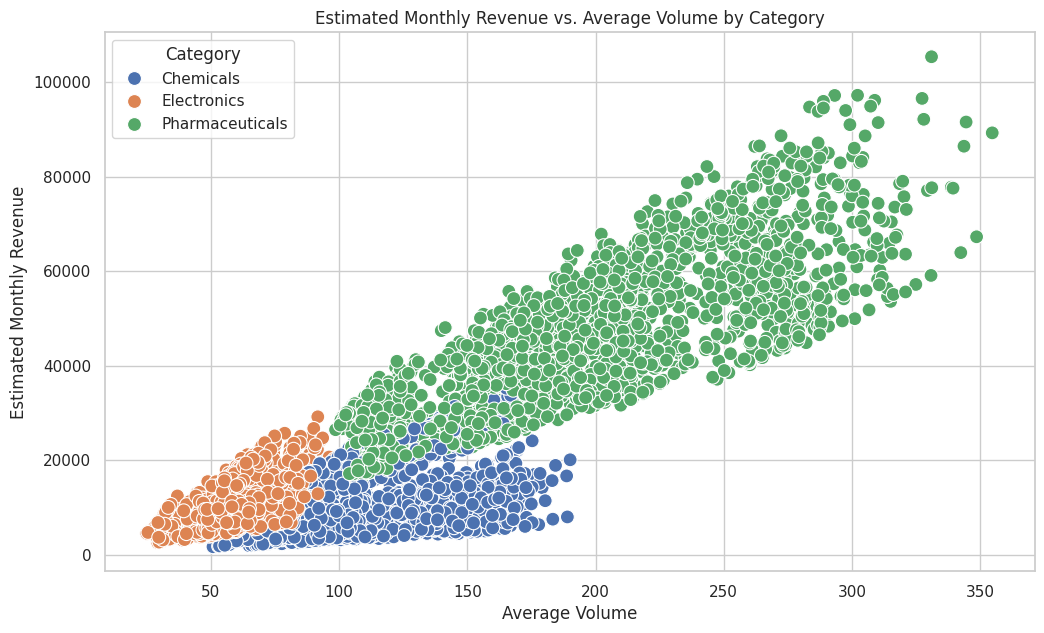

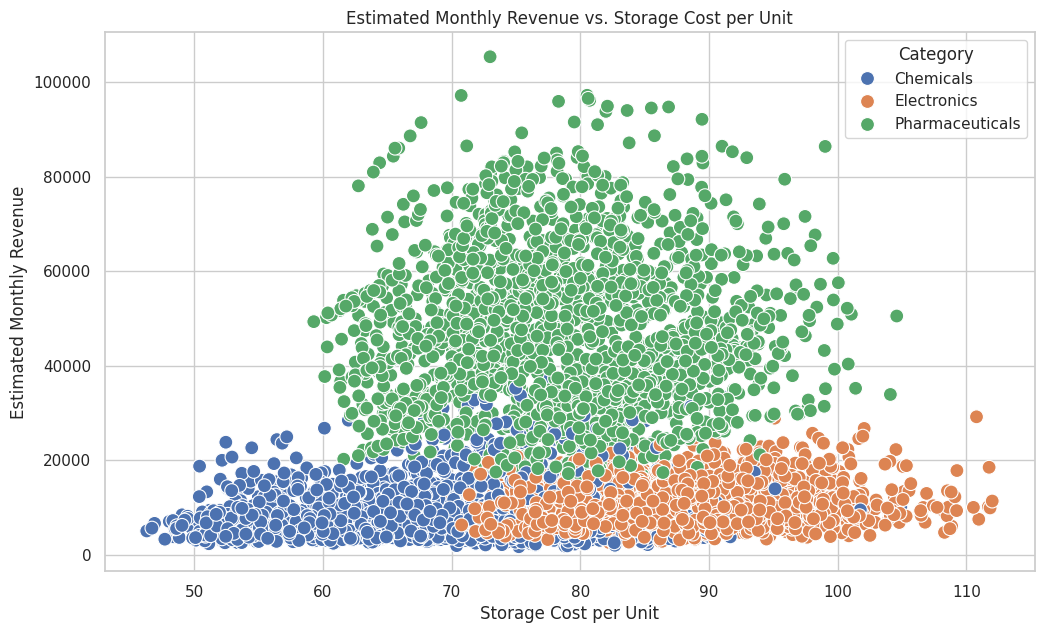

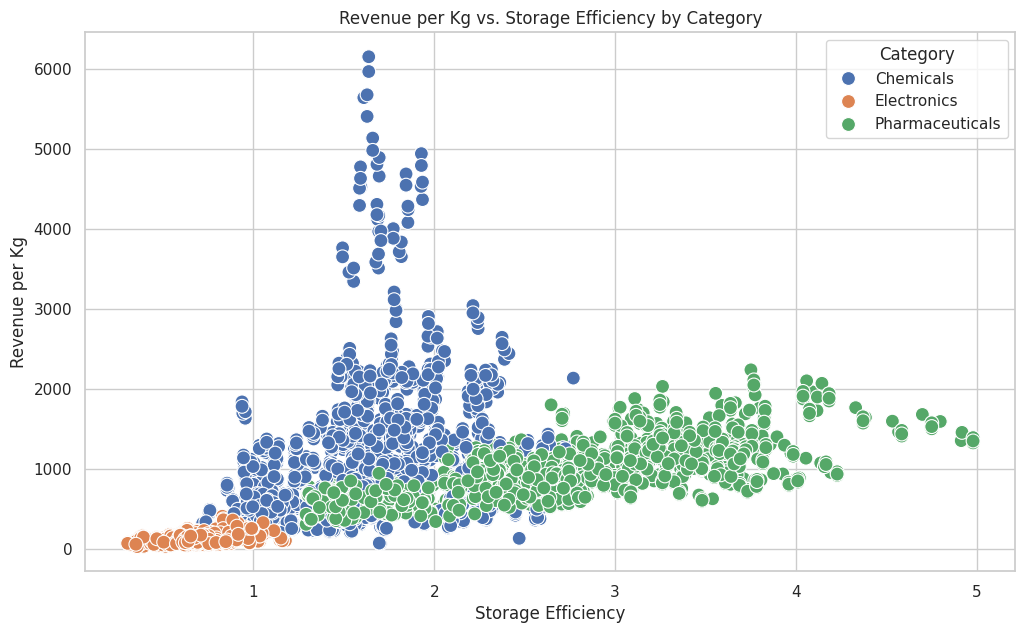

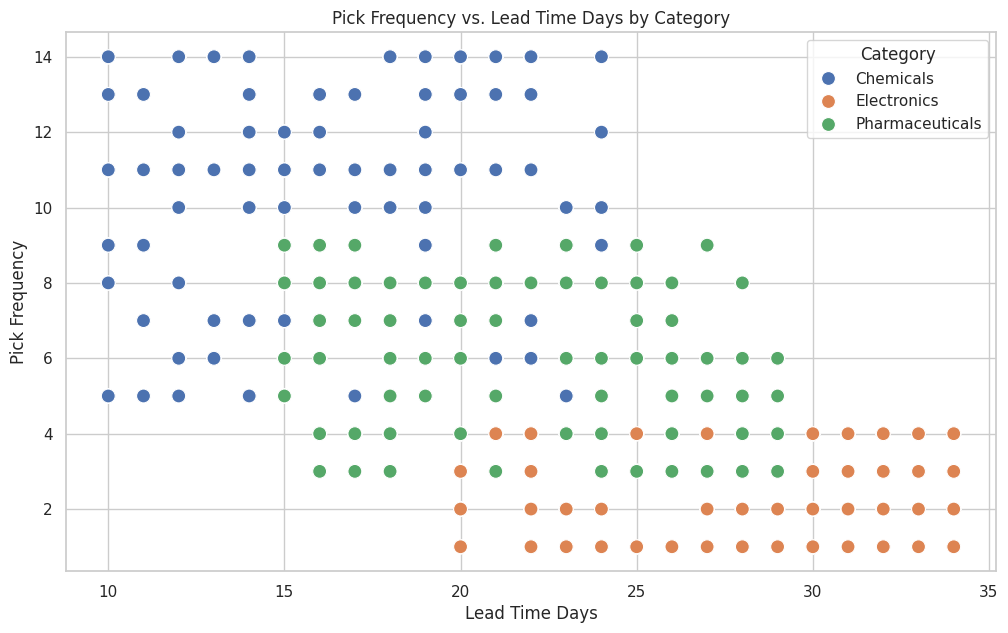

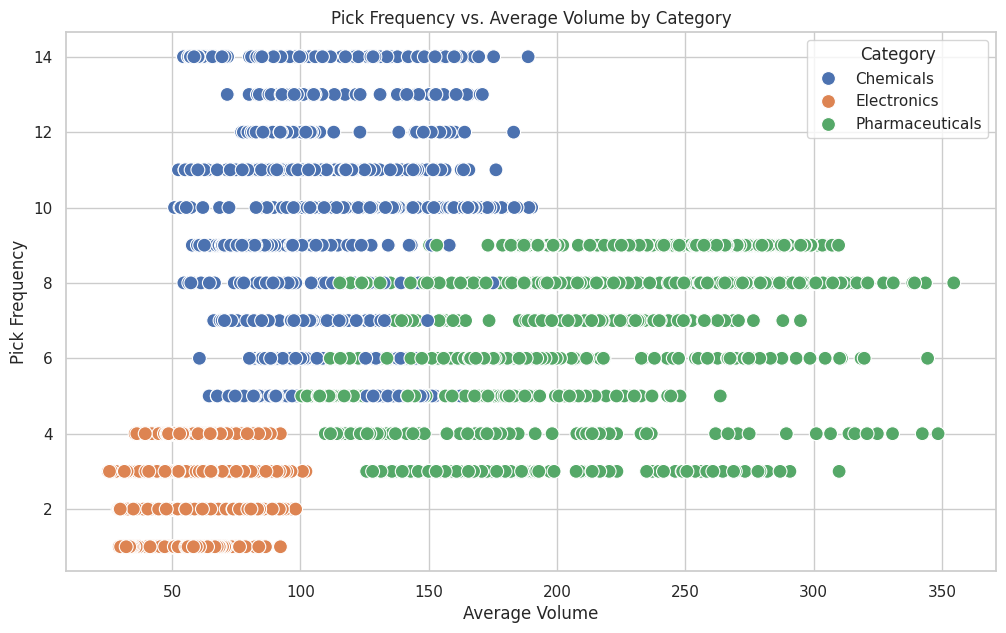

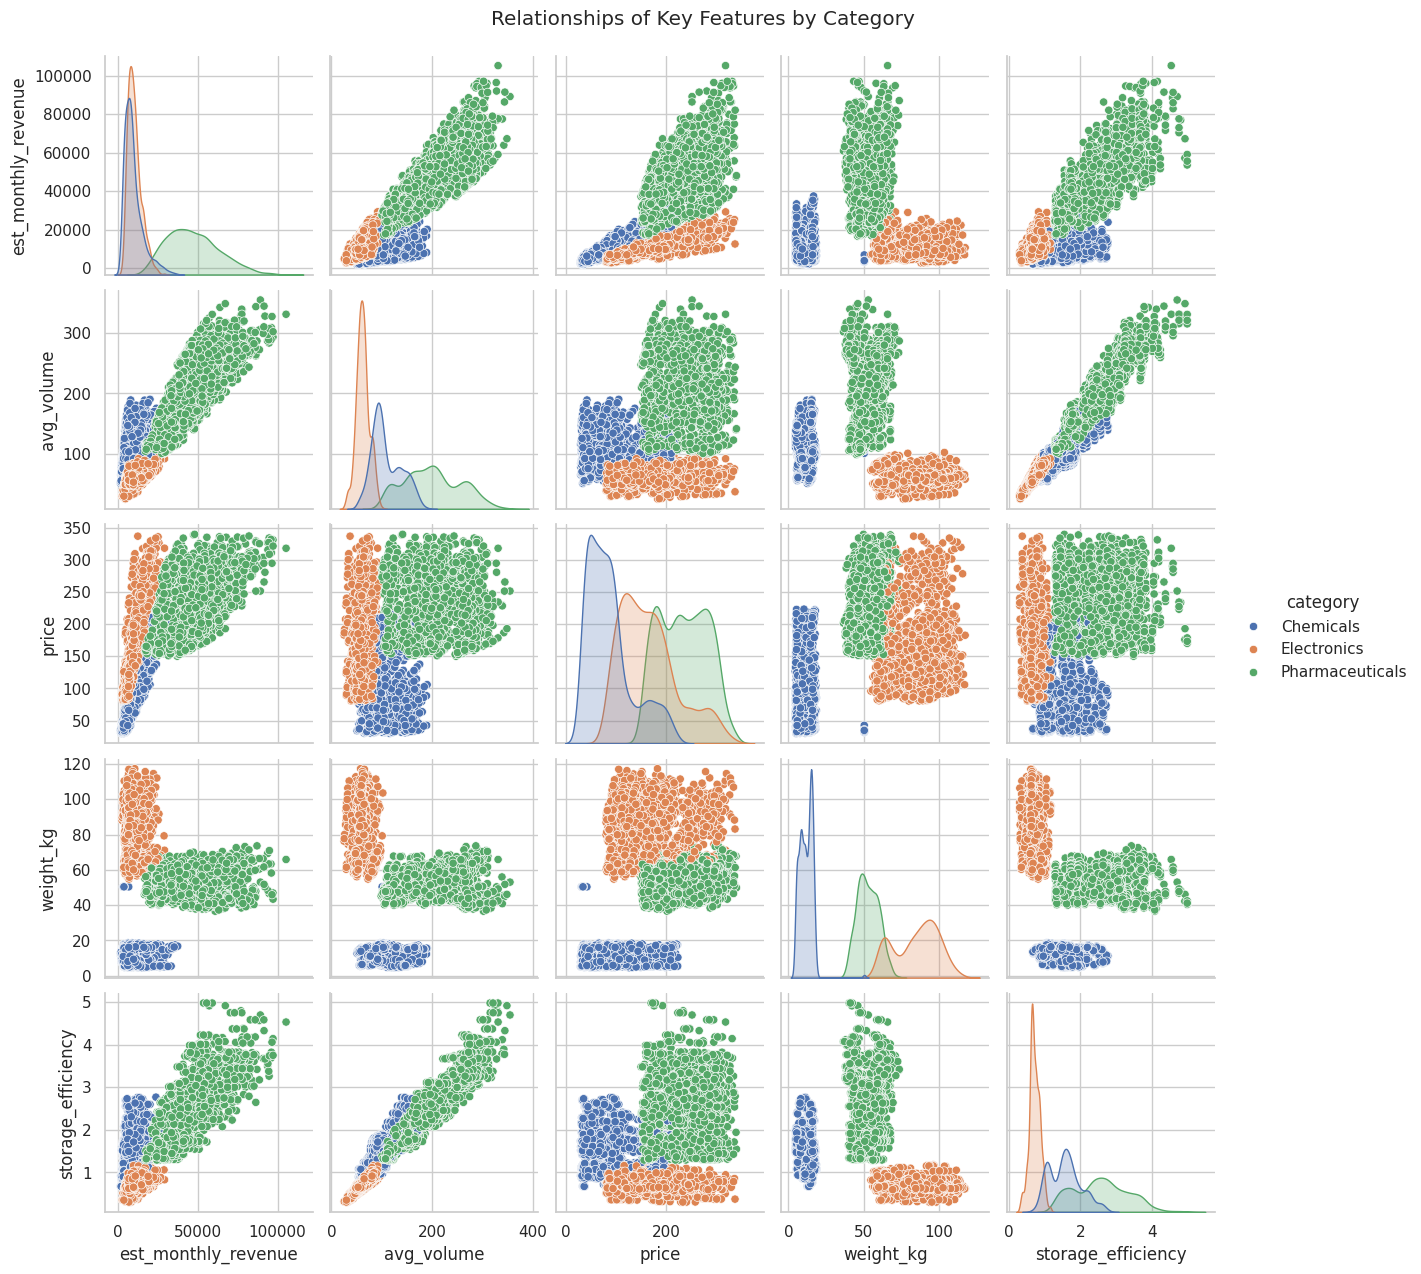

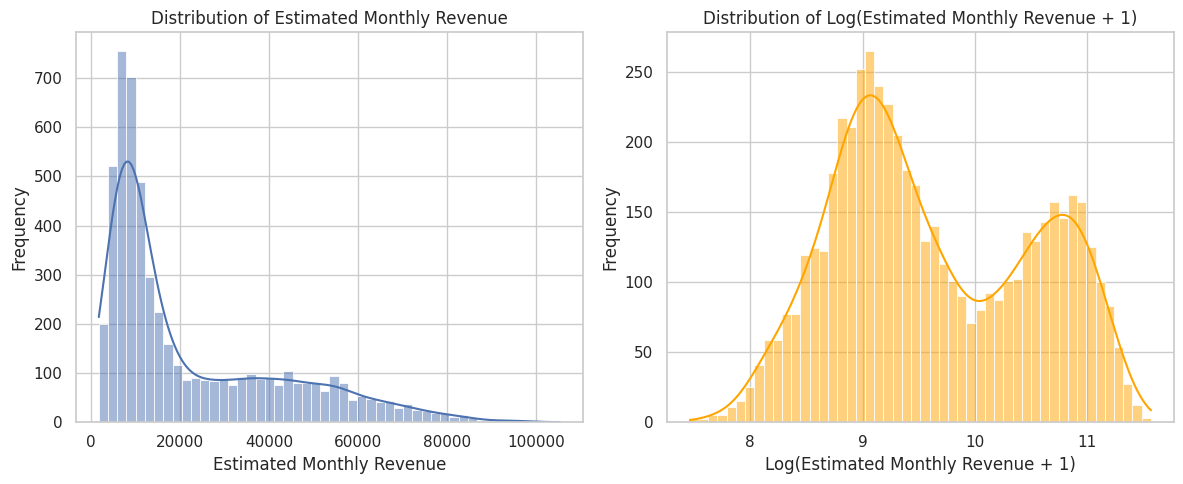

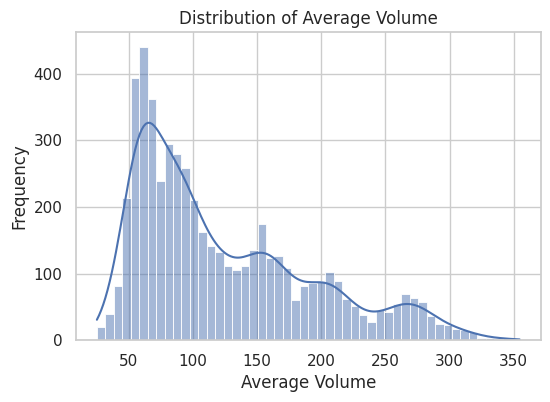

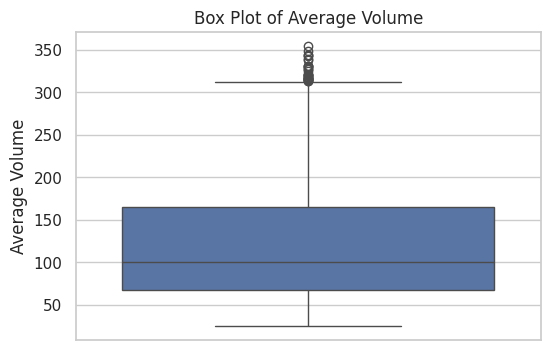

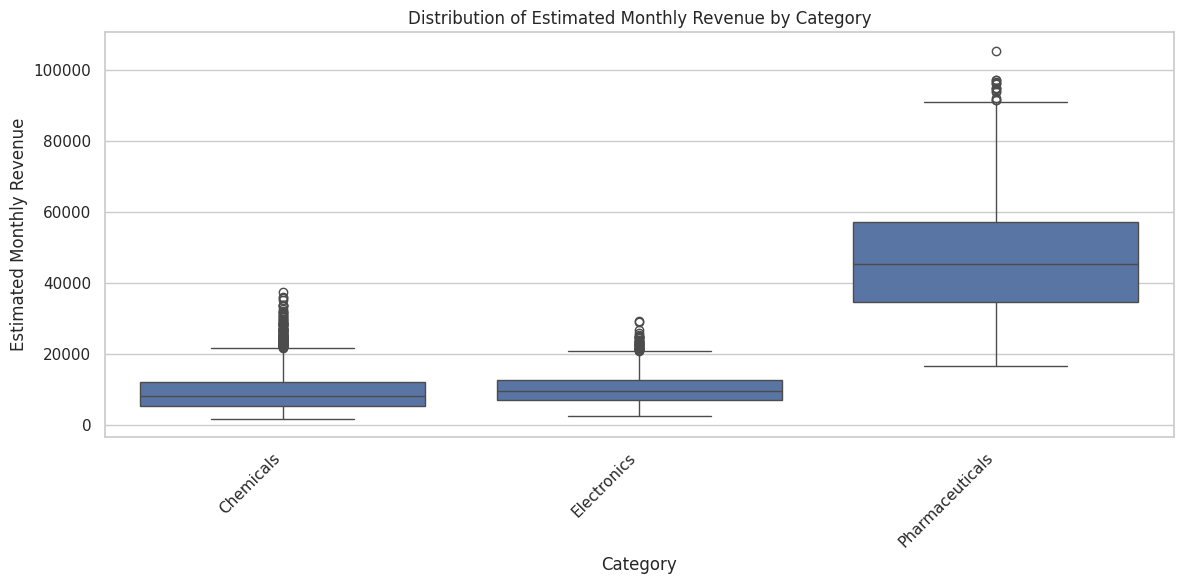

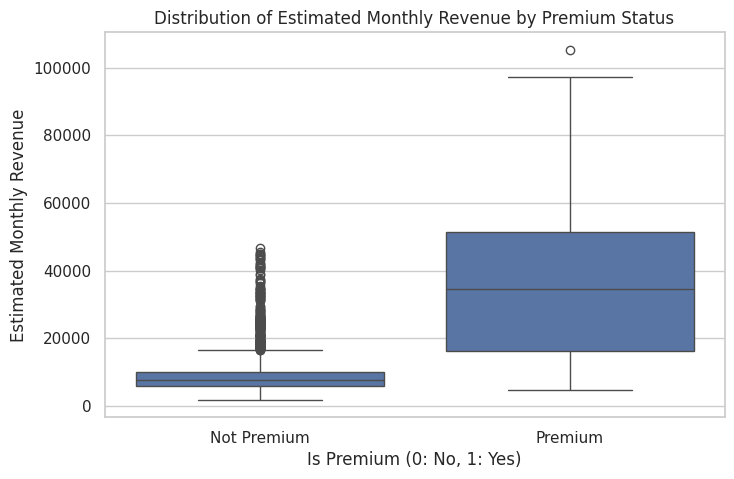

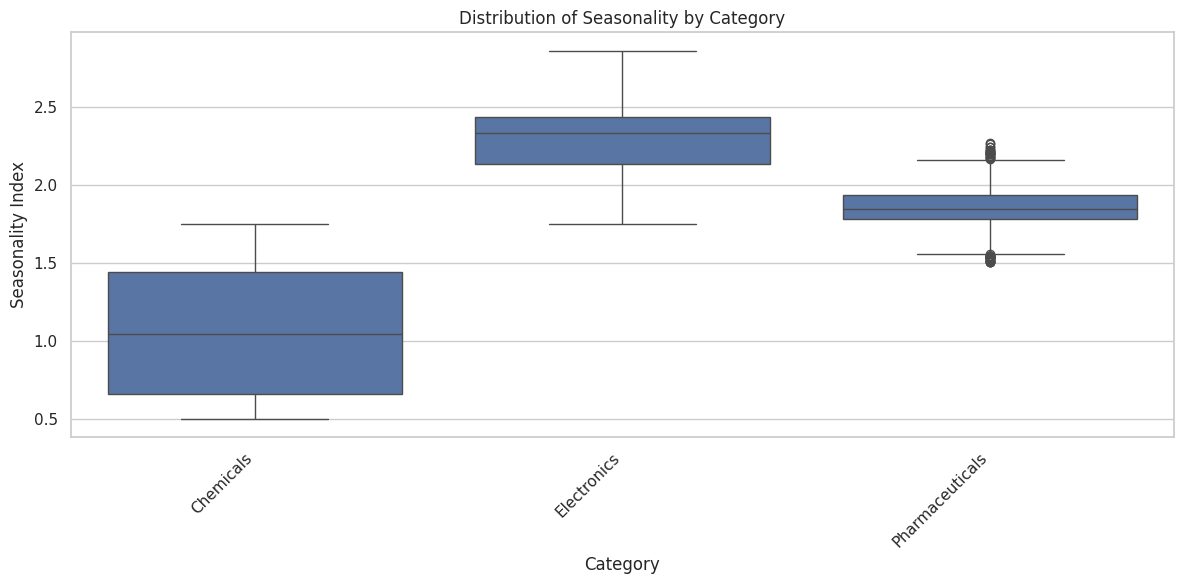

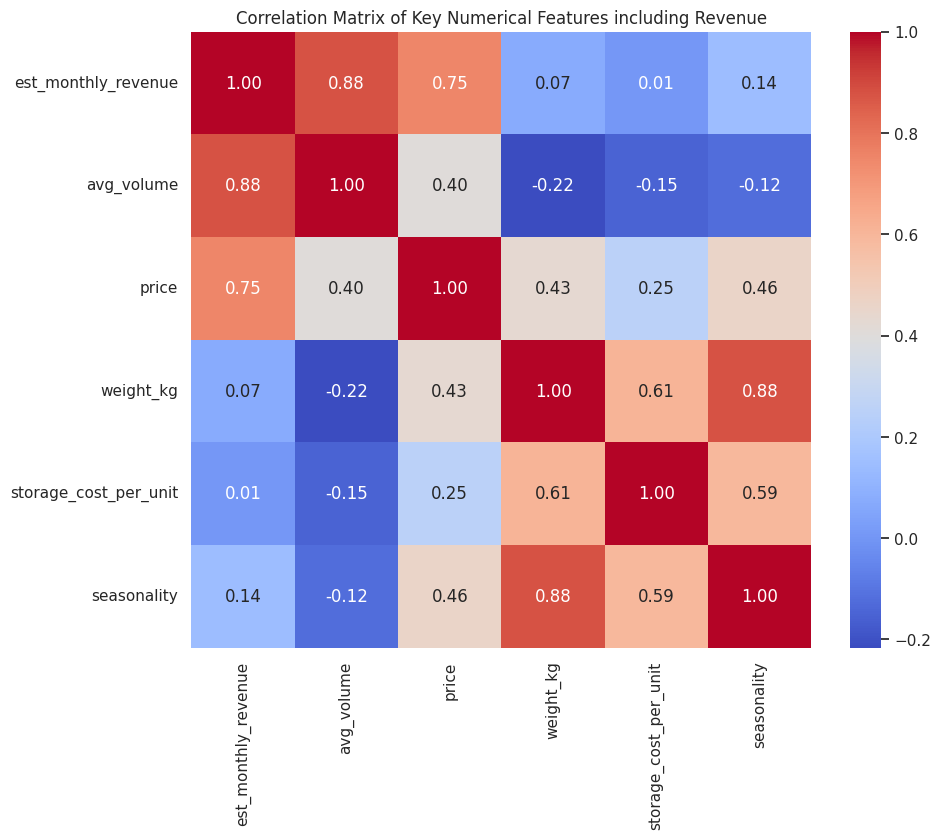

DataFrame after One-Hot Encoding:


,product_id,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,volume_cv,...,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity,log_est_monthly_revenue,category_Electronics,category_Pharmaceuticals
0,KN_TN__3747,52.0053,0.9185,9.4720,80.0615,60.5088,97.7895,50.4128,148.2023,0.5026,...,7829.174054,826.559761,1.616120,10.324060,0,0,108.837607,8.965740,False,False
1,KN_TN__1189,52.7922,0.8886,9.8132,86.6778,61.5188,92.2037,55.2073,147.4110,0.6194,...,7992.013868,814.414652,1.498789,9.395885,0,0,108.837607,8.986323,False,False
2,KN_TN__4005,50.5289,0.9001,9.0921,87.7028,61.6051,99.1147,51.6780,150.7927,0.5170,...,8692.636711,956.064794,1.608872,10.901189,0,0,108.837607,9.070347,False,False
3,KN_TN__8734,51.6537,1.0730,10.0799,71.0697,62.4003,99.1541,53.9300,153.0840,0.5555,...,7046.852141,699.099410,1.589000,9.836814,0,0,108.837607,8.860478,False,False
4,KN_TN__2528,58.4482,1.0421,12.1172,83.9347,70.7268,106.1848,61.9190,168.5895,0.6302,...,8912.589333,735.532081,1.501338,8.763147,0,0,108.837607,9.095332,False,False



Data Types after Encoding:
product_id                          object
base_volume                        float64
seasonality                        float64
weight_kg                          float64
price                              float64
storage_cost_per_unit              float64
avg_volume                         float64
volume_std                         float64
total_volume                       float64
volume_cv                          float64
storage_type                        object
pick_frequency                       int64
lead_time_days                       int64
Received date               datetime64[ns]
Month                                int64
Year                                 int64
est_monthly_revenue                float64
rev_per_kg                         float64
storage_efficiency                 float64
volume_weight_ratio                float64
is_premium                           int64
high_seasonality                     int64
category_popularity       

,product_id,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,volume_cv,...,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity,log_est_monthly_revenue,category_Electronics,category_Pharmaceuticals
0,KN_TN__3747,52.0053,0.9185,9.4720,80.0615,60.5088,97.7895,50.4128,148.2023,0.5026,...,7829.174054,826.559761,1.616120,10.324060,0,0,108.837607,8.965740,0,0
1,KN_TN__1189,52.7922,0.8886,9.8132,86.6778,61.5188,92.2037,55.2073,147.4110,0.6194,...,7992.013868,814.414652,1.498789,9.395885,0,0,108.837607,8.986323,0,0
2,KN_TN__4005,50.5289,0.9001,9.0921,87.7028,61.6051,99.1147,51.6780,150.7927,0.5170,...,8692.636711,956.064794,1.608872,10.901189,0,0,108.837607,9.070347,0,0
3,KN_TN__8734,51.6537,1.0730,10.0799,71.0697,62.4003,99.1541,53.9300,153.0840,0.5555,...,7046.852141,699.099410,1.589000,9.836814,0,0,108.837607,8.860478,0,0
4,KN_TN__2528,58.4482,1.0421,12.1172,83.9347,70.7268,106.1848,61.9190,168.5895,0.6302,...,8912.589333,735.532081,1.501338,8.763147,0,0,108.837607,9.095332,0,0



Data Types after encoding:
product_id                          object
base_volume                        float64
seasonality                        float64
weight_kg                          float64
price                              float64
storage_cost_per_unit              float64
avg_volume                         float64
volume_std                         float64
total_volume                       float64
volume_cv                          float64
storage_type                        object
pick_frequency                       int64
lead_time_days                       int64
Received date               datetime64[ns]
Month                                int64
Year                                 int64
est_monthly_revenue                float64
rev_per_kg                         float64
storage_efficiency                 float64
volume_weight_ratio                float64
is_premium                           int64
high_seasonality                     int64
category_popularity       

,product_id,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,volume_cv,...,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity,log_est_monthly_revenue,category_Electronics,category_Pharmaceuticals
0,KN_TN__3747,52.0053,0.9185,9.4720,80.0615,60.5088,97.7895,50.4128,148.2023,0.5026,...,7829.174054,826.559761,1.616120,10.324060,0,0,108.837607,8.965740,0,0
1,KN_TN__1189,52.7922,0.8886,9.8132,86.6778,61.5188,92.2037,55.2073,147.4110,0.6194,...,7992.013868,814.414652,1.498789,9.395885,0,0,108.837607,8.986323,0,0
2,KN_TN__4005,50.5289,0.9001,9.0921,87.7028,61.6051,99.1147,51.6780,150.7927,0.5170,...,8692.636711,956.064794,1.608872,10.901189,0,0,108.837607,9.070347,0,0
3,KN_TN__8734,51.6537,1.0730,10.0799,71.0697,62.4003,99.1541,53.9300,153.0840,0.5555,...,7046.852141,699.099410,1.589000,9.836814,0,0,108.837607,8.860478,0,0
4,KN_TN__2528,58.4482,1.0421,12.1172,83.9347,70.7268,106.1848,61.9190,168.5895,0.6302,...,8912.589333,735.532081,1.501338,8.763147,0,0,108.837607,9.095332,0,0


First 5 rows of scaled features:


array([[-0.45379234, -1.47529933, -1.31851033, -1.09324013, -1.77480803,
        -0.38518274, -0.32978764, -0.38276662, -0.21512166,  1.54093849,
        -0.67328755, -1.59608507, -0.69820985, -0.74684478,  0.41808718,
         0.01351568,  1.2462718 , -0.99981575, -2.16671375, -0.25966638,
        -0.776007  , -0.71562586, -0.71444871],
       [-0.43127974, -1.52872616, -1.3074438 , -1.00659954, -1.67781678,
        -0.47006068, -0.19527114, -0.39101239,  0.41373078,  1.54093849,
        -0.67328755, -1.30271809, -0.69820985, -0.73827619,  0.39314482,
        -0.12092109,  1.03767362, -0.99981575, -2.16671375, -0.25966638,
        -0.75205111, -0.71562586, -0.71444871],
       [-0.49603101, -1.50817738, -1.33083205, -0.99317714, -1.66952931,
        -0.36504592, -0.29429066, -0.35577325, -0.13759191,  1.54093849,
        -0.67328755, -1.0093511 , -0.69820985, -0.70140963,  0.68405113,
         0.00521028,  1.37597572, -0.99981575, -2.16671375, -0.25966638,
        -0.65425965, -0.7156

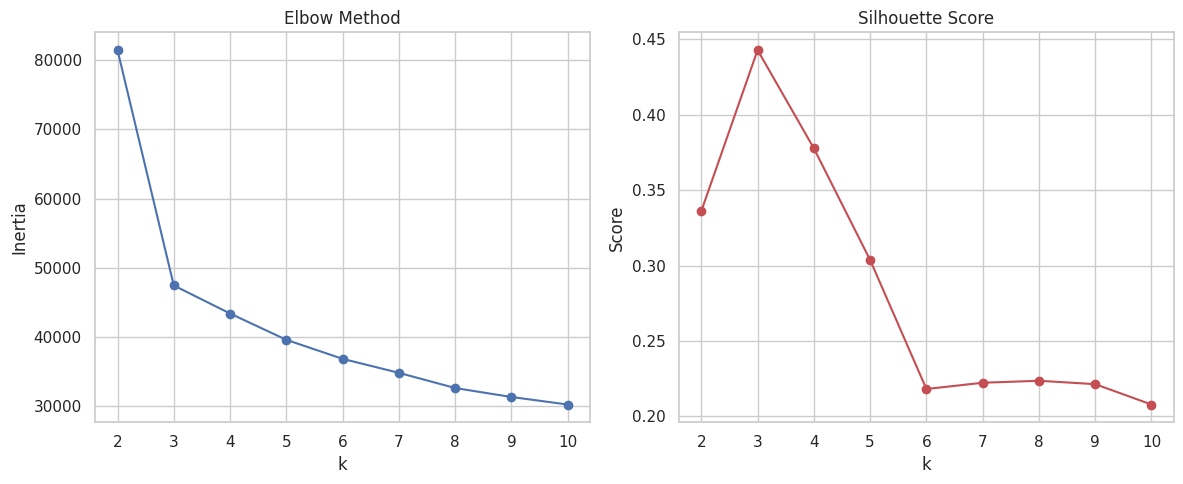

Optimal number of clusters based on silhouette score: 3
Cluster counts:
cluster
0    1838
1    1834
2    1755
Name: count, dtype: int64
Mean values of features by cluster:


,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,volume_cv,pick_frequency,...,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity,log_est_monthly_revenue,category_Electronics,category_Pharmaceuticals
cluster,,,,,,,,,,,,,,,,,,,,,
0,33.193186,2.277996,84.071598,165.561747,86.640198,62.959192,28.575894,91.442942,0.495513,2.686616,...,10323.576077,127.410185,0.728833,0.768562,0.448857,1.00000,61.963672,9.162023,1.0,0.0
1,111.020501,1.861682,52.744191,233.044528,78.634240,197.133346,96.139955,292.287344,0.528107,6.381134,...,45509.647935,896.336789,2.519225,3.858328,0.934569,1.00000,200.230782,10.675663,0.0,1.0
2,59.084774,1.062210,11.832605,88.810053,71.351092,108.837607,61.845281,170.661529,0.606923,9.017664,...,9730.080014,856.330896,1.565136,9.940195,0.099145,0.45698,108.837607,9.035087,0.0,0.0


Cluster means with descriptive names:


,base_volume,seasonality,weight_kg,price,storage_cost_per_unit,avg_volume,volume_std,total_volume,volume_cv,pick_frequency,...,est_monthly_revenue,rev_per_kg,storage_efficiency,volume_weight_ratio,is_premium,high_seasonality,category_popularity,log_est_monthly_revenue,category_Electronics,category_Pharmaceuticals
cluster,,,,,,,,,,,,,,,,,,,,,
Low-Value Chemicals,33.193186,2.277996,84.071598,165.561747,86.640198,62.959192,28.575894,91.442942,0.495513,2.686616,...,10323.576077,127.410185,0.728833,0.768562,0.448857,1.00000,61.963672,9.162023,1.0,0.0
High-Value Pharmaceuticals,111.020501,1.861682,52.744191,233.044528,78.634240,197.133346,96.139955,292.287344,0.528107,6.381134,...,45509.647935,896.336789,2.519225,3.858328,0.934569,1.00000,200.230782,10.675663,0.0,1.0
Mid-Value Electronics,59.084774,1.062210,11.832605,88.810053,71.351092,108.837607,61.845281,170.661529,0.606923,9.017664,...,9730.080014,856.330896,1.565136,9.940195,0.099145,0.45698,108.837607,9.035087,0.0,0.0


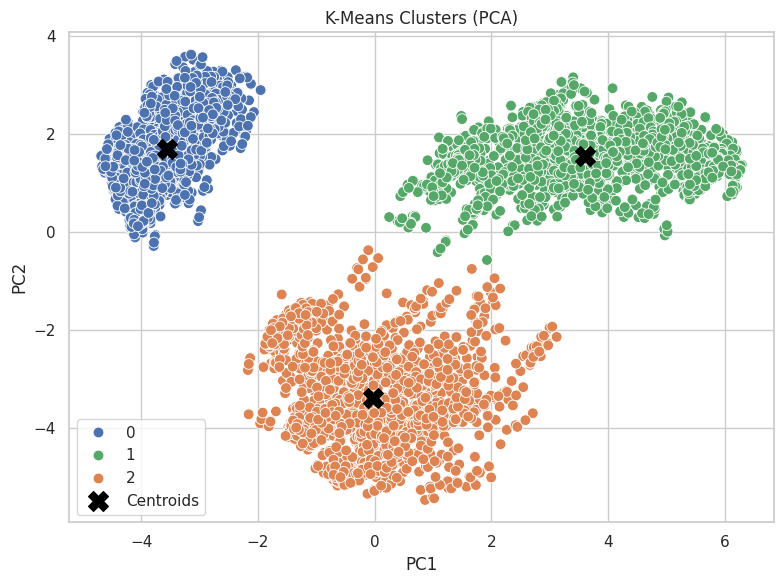


Cluster 0 (Low-Value Chemicals):
  Products: 1838
  Average Volume: 63.0
  Average Price: £165.56
  Volume CV: 0.50
  Storage Efficiency: 0.73
  Average Weight: 84.07 kg
  Average Pick Frequency: 2.7
  Average Lead Time: 28.0 days
  Recommendation: Store in high-access zones near picking/packing. Focus on efficient flow due to high pick frequency and low handling cost.

Cluster 1 (High-Value Pharmaceuticals):
  Products: 1834
  Average Volume: 197.1
  Average Price: £233.04
  Volume CV: 0.53
  Storage Efficiency: 2.52
  Average Weight: 52.74 kg
  Average Pick Frequency: 6.4
  Average Lead Time: 22.3 days
  Recommendation: Store in moderately accessible, secure zones that can handle higher volumes. Balance security for high-price items with reasonable access for moderate pick frequency.

Cluster 2 (Mid-Value Electronics):
  Products: 1755
  Average Volume: 108.8
  Average Price: £88.81
  Volume CV: 0.61
  Storage Efficiency: 1.57
  Average Weight: 11.83 kg
  Average Pick Frequency: 9.0

cluster  Received date
0        2020-01-31       1943.950103
         2020-02-29       1716.538497
         2020-03-31       1880.343276
         2020-04-30       1901.913265
         2020-05-31       2065.612251
Name: monthly_volume, dtype: float64

Index type: object
Sample index values: MultiIndex([(0, '2020-01-31'),
            (0, '2020-02-29'),
            (0, '2020-03-31'),
            (0, '2020-04-30'),
            (0, '2020-05-31')],
           names=['cluster', 'Received date'])
Cluster 0 ADF p-value: 0.9863 → Non-Stationary (fail to reject H₀)
Cluster 1 ADF p-value: 0.8693 → Non-Stationary (fail to reject H₀)
Cluster 2 ADF p-value: 0.9302 → Non-Stationary (fail to reject H₀)


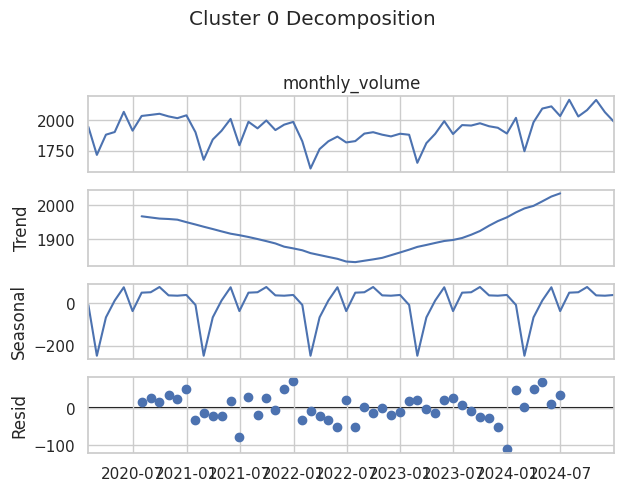

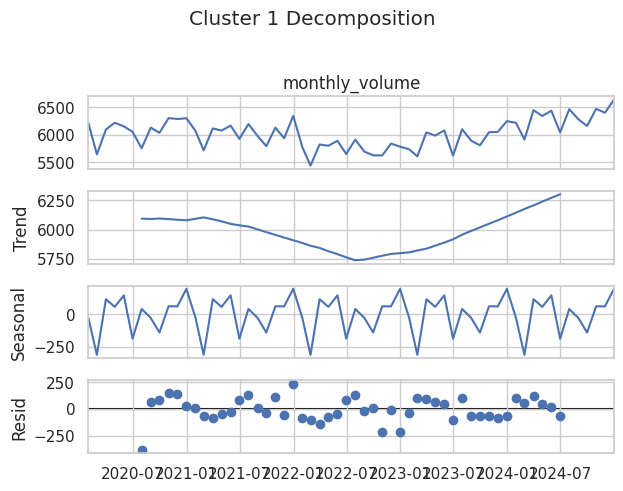

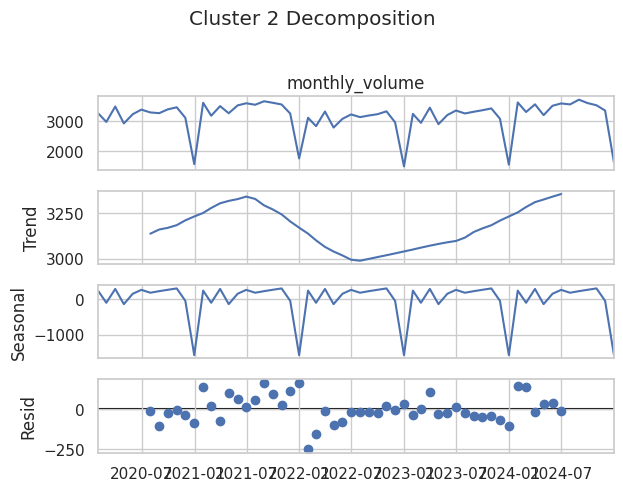

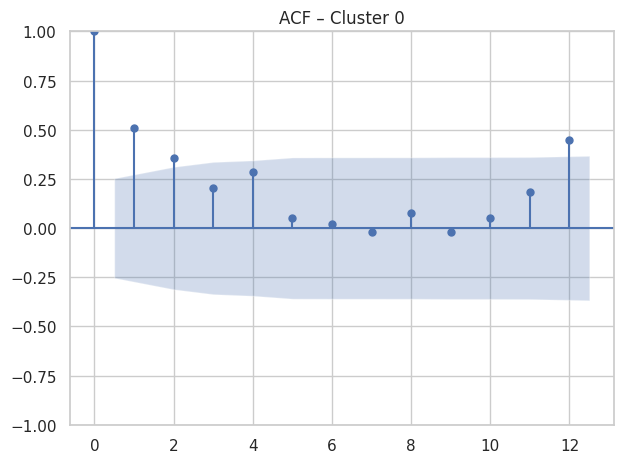

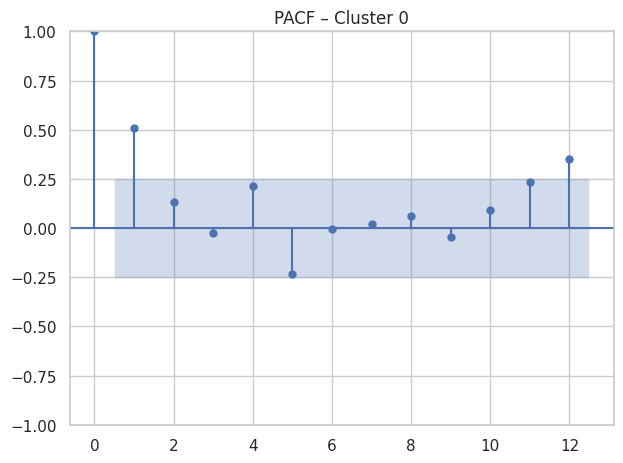

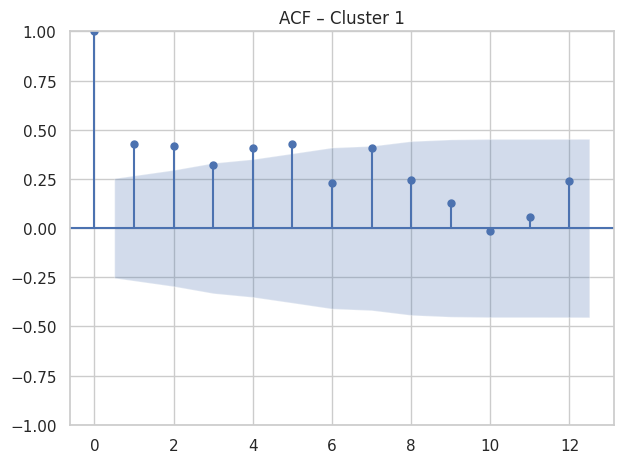

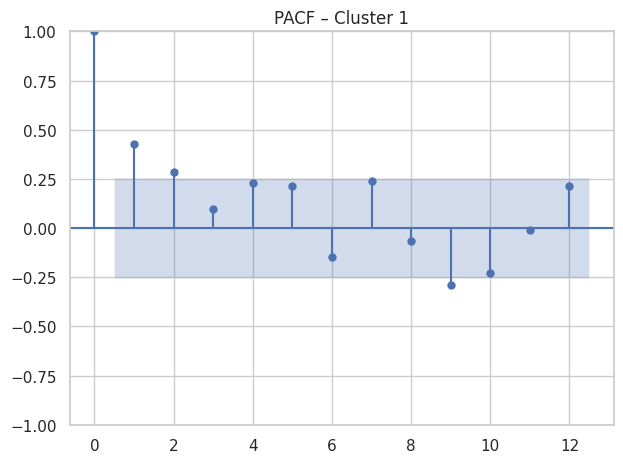

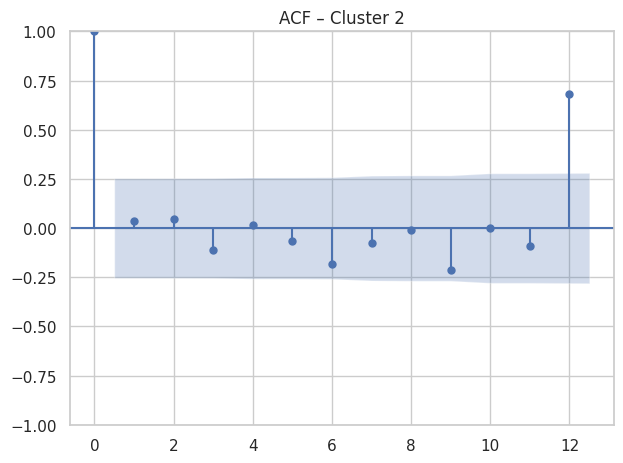

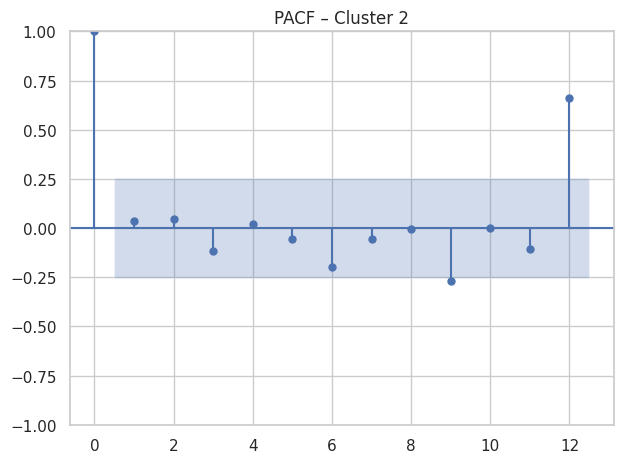

 Cluster 0:
   Training set: 48 months (2020-01 to 2023-12)
   Test set:     12 months (2024-01 to 2024-12)
----------------------------------------
 Cluster 1:
   Training set: 48 months (2020-01 to 2023-12)
   Test set:     12 months (2024-01 to 2024-12)
----------------------------------------
 Cluster 2:
   Training set: 48 months (2020-01 to 2023-12)
   Test set:     12 months (2024-01 to 2024-12)
----------------------------------------
Cluster 0 → Best MAE: 16.5064
Best order: (1, 0, 0), Seasonal: (0, 0, 0, 12)
Cluster 1 → Best MAE: 47.9791
Best order: (0, 1, 0), Seasonal: (1, 1, 1, 12)
Cluster 2 → Best MAE: 10.3691
Best order: (0, 1, 0), Seasonal: (1, 0, 1, 12)

Training final SARIMAX model for Cluster 0...
Forecast completed for Cluster 0

Training final SARIMAX model for Cluster 1...
Forecast completed for Cluster 1

Training final SARIMAX model for Cluster 2...
Forecast completed for Cluster 2

Residual Diagnostics for Cluster 0:


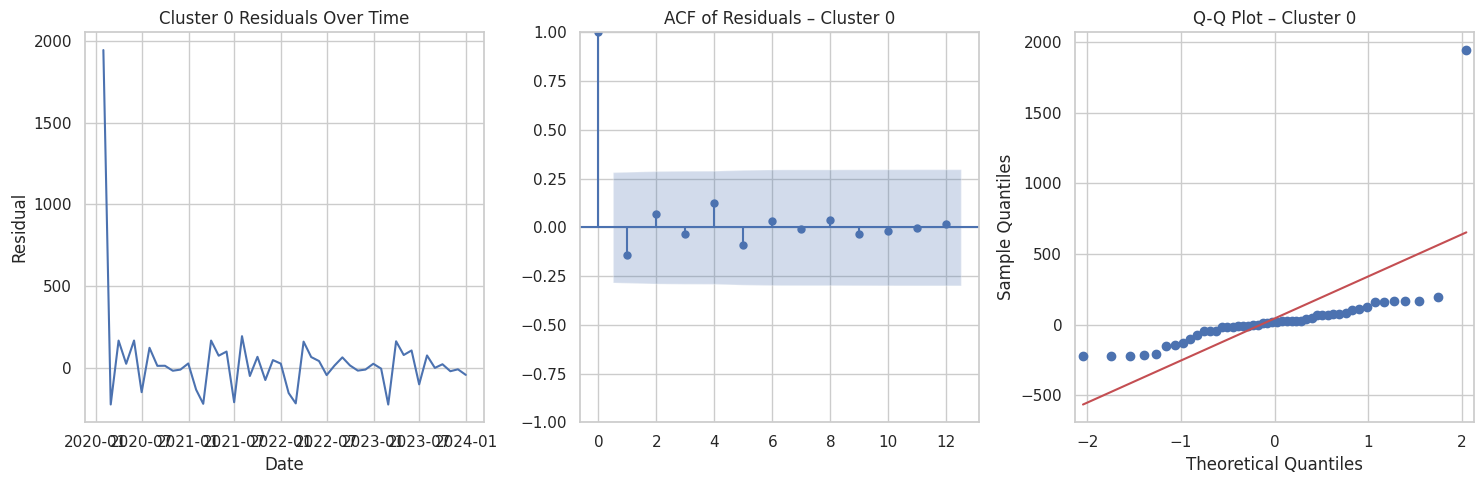

  Ljung-Box p-value (lag=12): 0.996
  Residuals appear random.
----------------------------------------

Residual Diagnostics for Cluster 1:


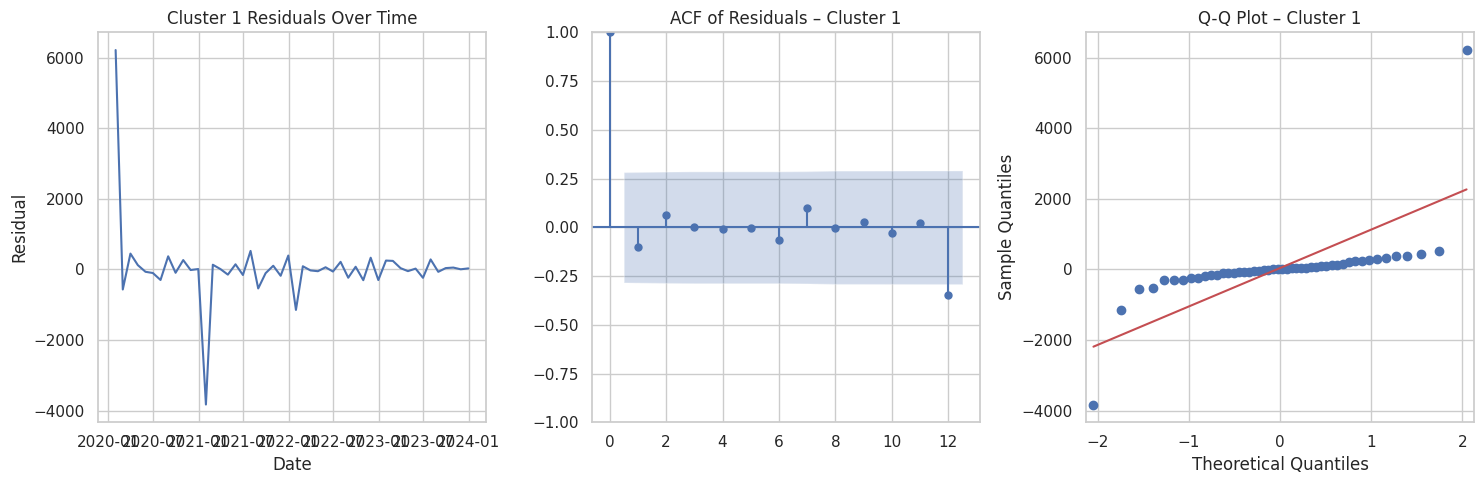

  Ljung-Box p-value (lag=12): 0.642
  Residuals appear random.
----------------------------------------

Residual Diagnostics for Cluster 2:


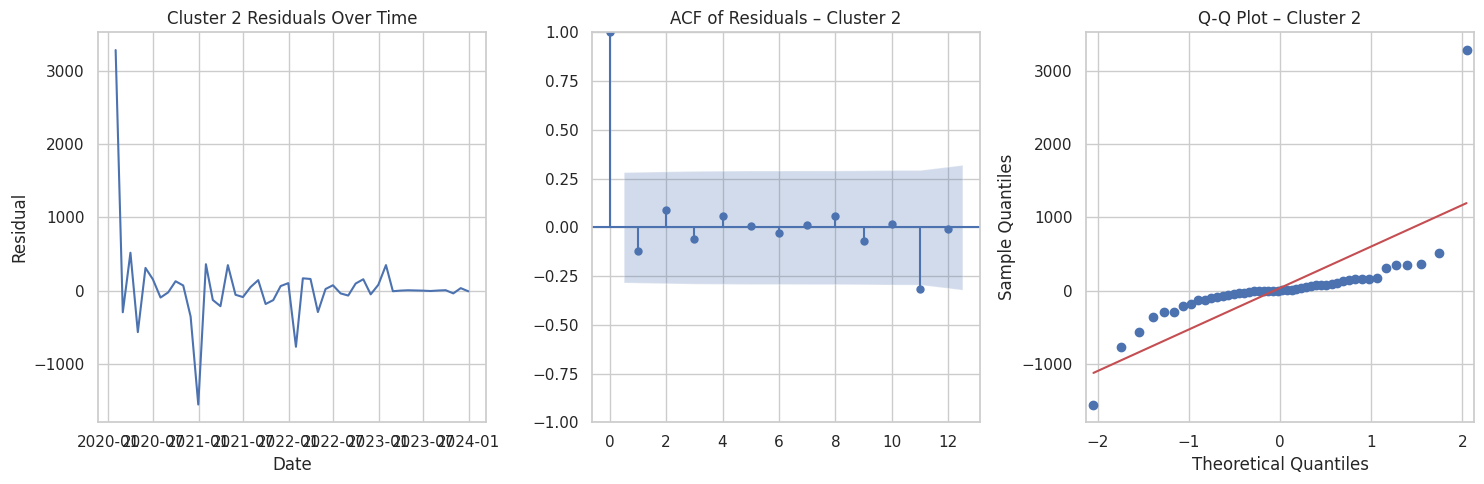

  Ljung-Box p-value (lag=12): 0.729
  Residuals appear random.
----------------------------------------
Generating forecasts for Cluster 0...
Forecast generated for Cluster 0 from 2024-01 to 2024-12.
------------------------------

Cluster 0 Forecasts (first 5 rows):
Received date
2024-01-31    1885.583100
2024-02-29    1881.251422
2024-03-31    1876.929696
2024-04-30    1872.617898
2024-05-31    1868.316005
Freq: ME, Name: predicted_mean, dtype: float64 

Generating forecasts for Cluster 1...
Forecast generated for Cluster 1 from 2024-01 to 2024-12.
------------------------------

Cluster 1 Forecasts (first 5 rows):
Received date
2024-01-31    5980.865999
2024-02-29    5716.091454
2024-03-31    6124.187421
2024-04-30    6089.691773
2024-05-31    6175.592477
Freq: ME, Name: predicted_mean, dtype: float64 

Generating forecasts for Cluster 2...
Forecast generated for Cluster 2 from 2024-01 to 2024-12.
------------------------------

Cluster 2 Forecasts (first 5 rows):
Received date
2024

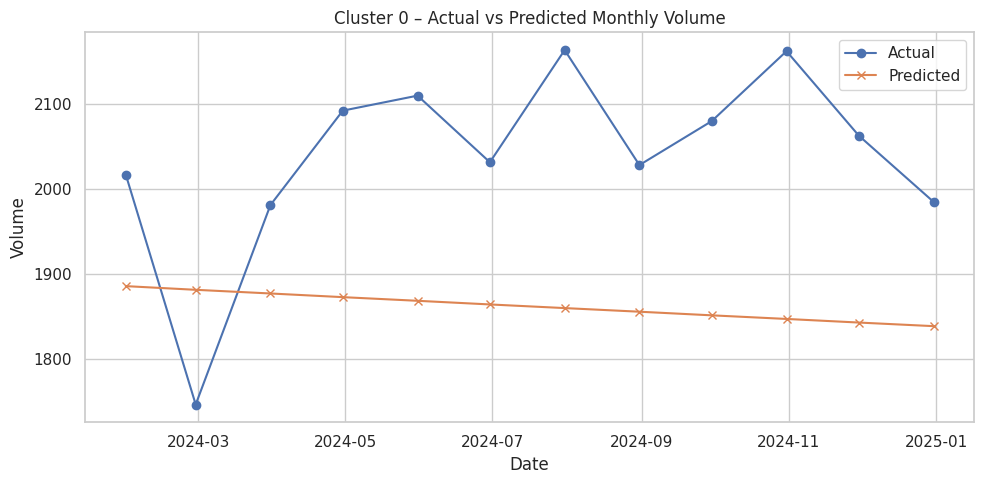

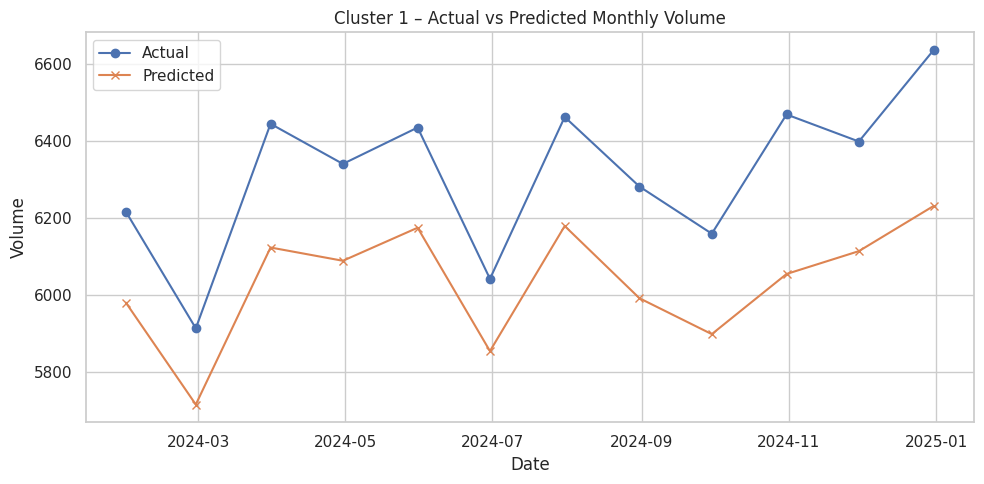

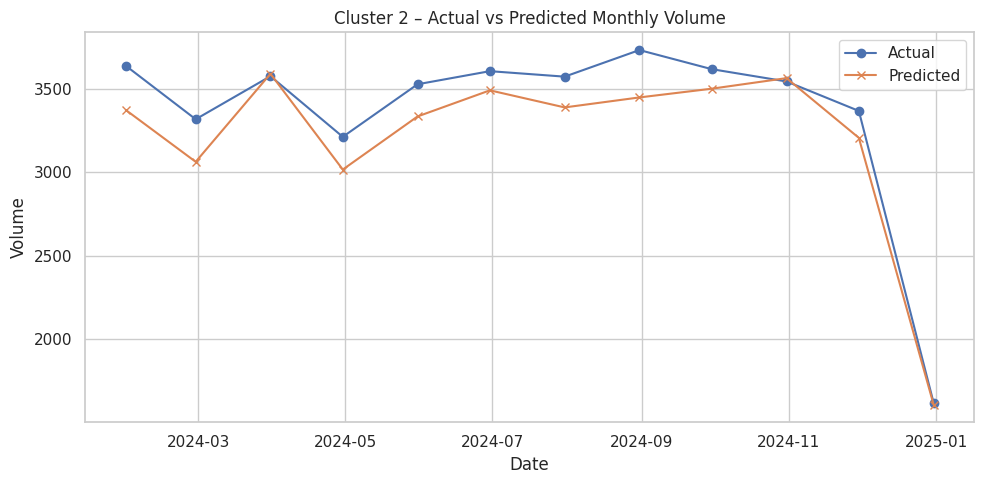


 Cluster 0 Evaluation:
  MAE:  198.76
  RMSE: 209.01
  MAPE: 9.65%
  MAE as % of Test Mean: 9.75%

 Cluster 1 Evaluation:
  MAE:  282.94
  RMSE: 290.81
  MAPE: 4.46%
  MAE as % of Test Mean: 4.48%

 Cluster 2 Evaluation:
  MAE:  150.97
  RMSE: 177.38
  MAPE: 4.34%
  MAE as % of Test Mean: 4.49%


,MAE,RMSE,MAPE,Test_Mean,MAE_%
0,198.759866,209.007379,9.652180,2038.196656,9.751751
1,282.943217,290.813677,4.455842,6317.536002,4.478696
2,150.970802,177.379352,4.337454,3359.369588,4.494022


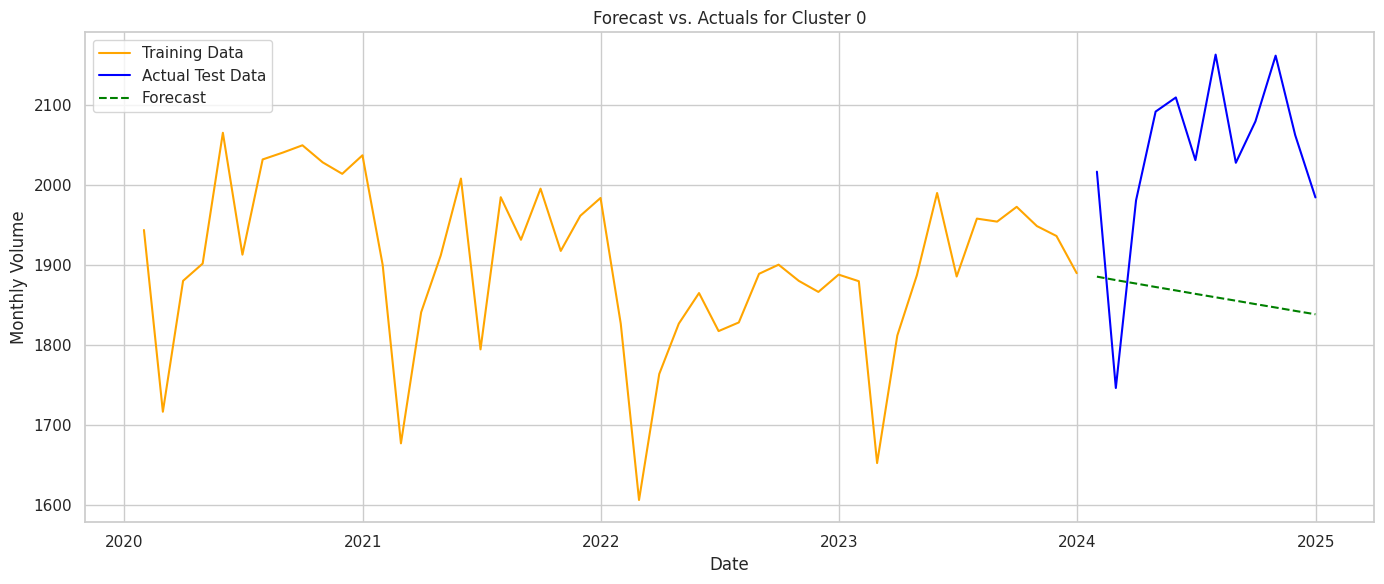

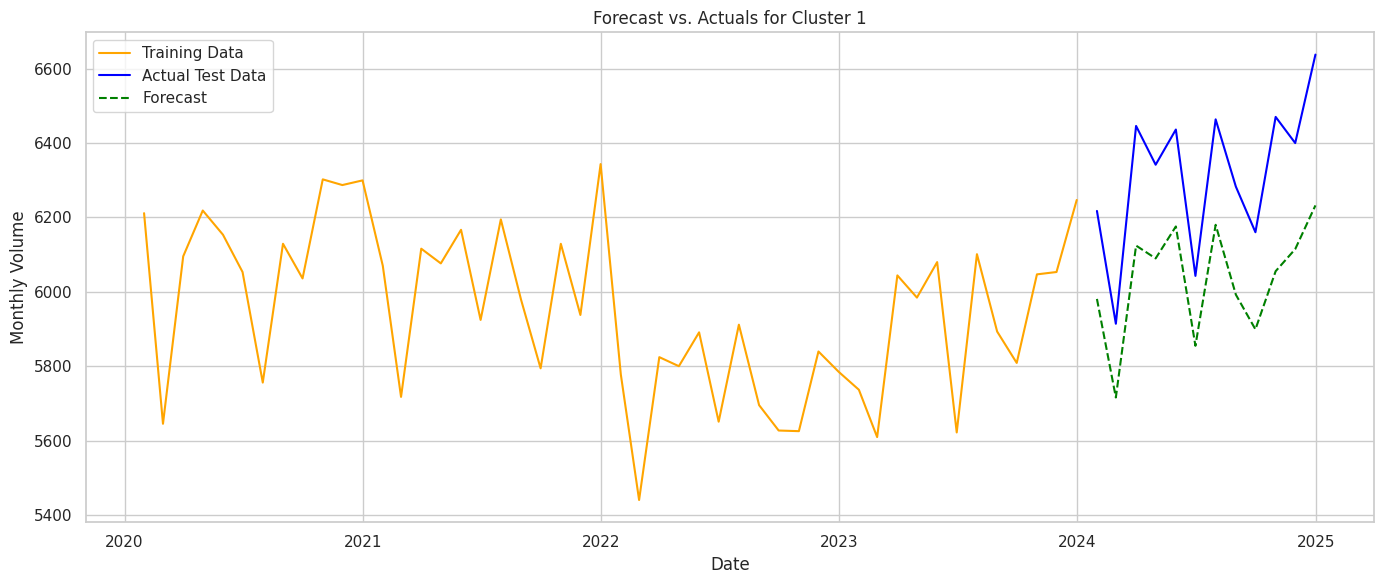

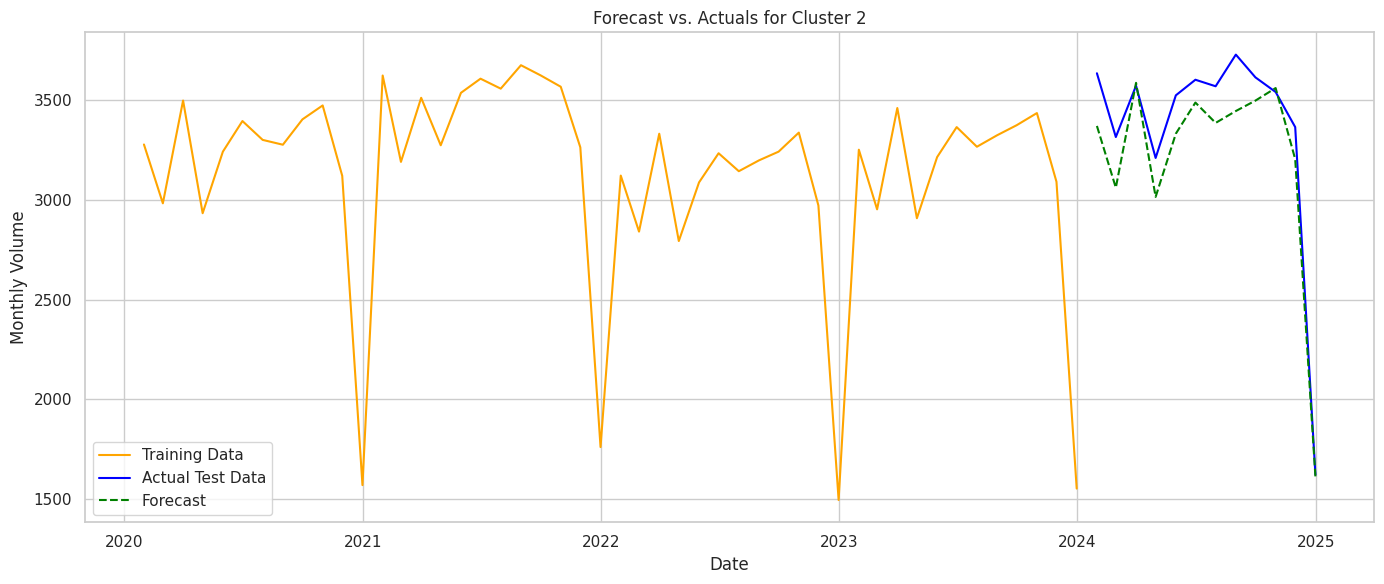

Preparing Prophet data for Cluster 0.


,ds,y
0,2020-01-31,1943.950103
1,2020-02-29,1716.538497
2,2020-03-31,1880.343276
3,2020-04-30,1901.913265
4,2020-05-31,2065.612251


Preparing Prophet data for Cluster 1.


,ds,y
0,2020-01-31,6211.282355
1,2020-02-29,5645.418037
2,2020-03-31,6095.250014
3,2020-04-30,6218.396127
4,2020-05-31,6153.347731


Preparing Prophet data for Cluster 2.


...

19:15:18 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/7b7vmvw2.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/8rz14ohy.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=92912', 'data', 'file=/tmp/tmpbqdngb7u/7b7vmvw2.json', 'init=/tmp/tmpbqdngb7u/8rz14ohy.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_modeldbj4ua3g/prophet_model-20250826191518.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:15:18 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


→ Done for Cluster 1
Training Prophet model for Cluster 2 on training data...


19:15:19 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


→ Done for Cluster 2
Forecasting for Cluster 0...
Forecast tail:


,ds,yhat,yhat_lower,yhat_upper
55,2024-08-31,2004.892448,1968.832127,2037.403512
56,2024-09-30,2032.091812,1999.045783,2066.549207
57,2024-10-31,1990.748943,1954.234688,2026.475144
58,2024-11-30,2011.684584,1975.322181,2050.324179
59,2024-12-31,2068.284711,2028.073335,2105.177402


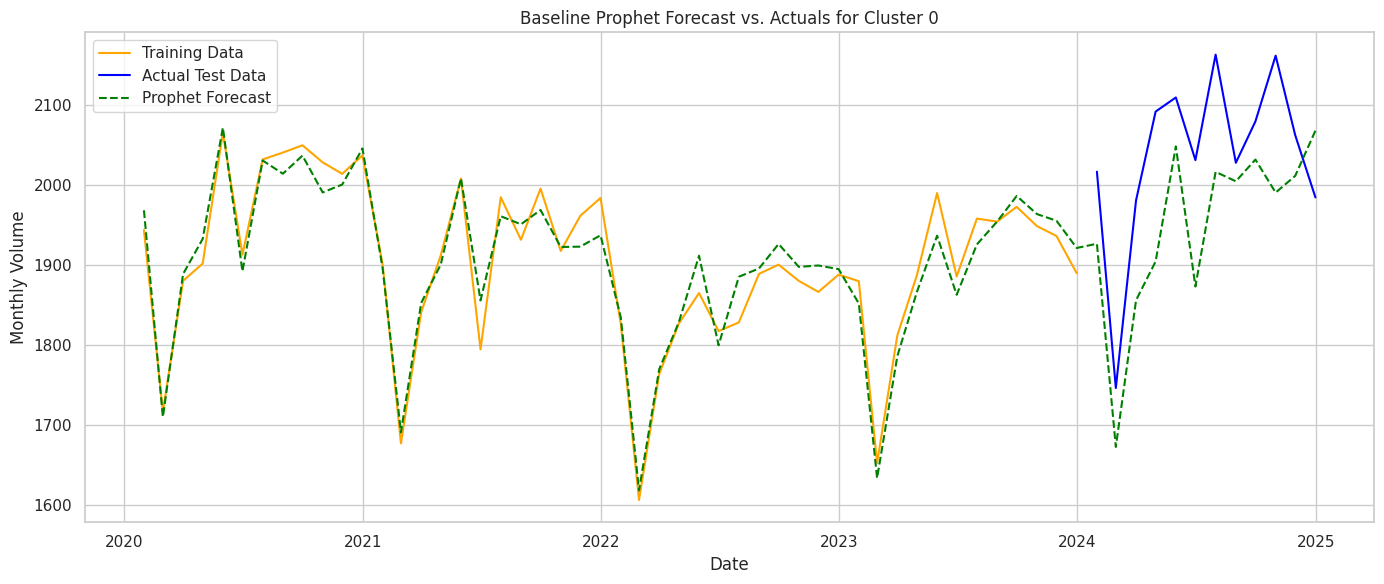

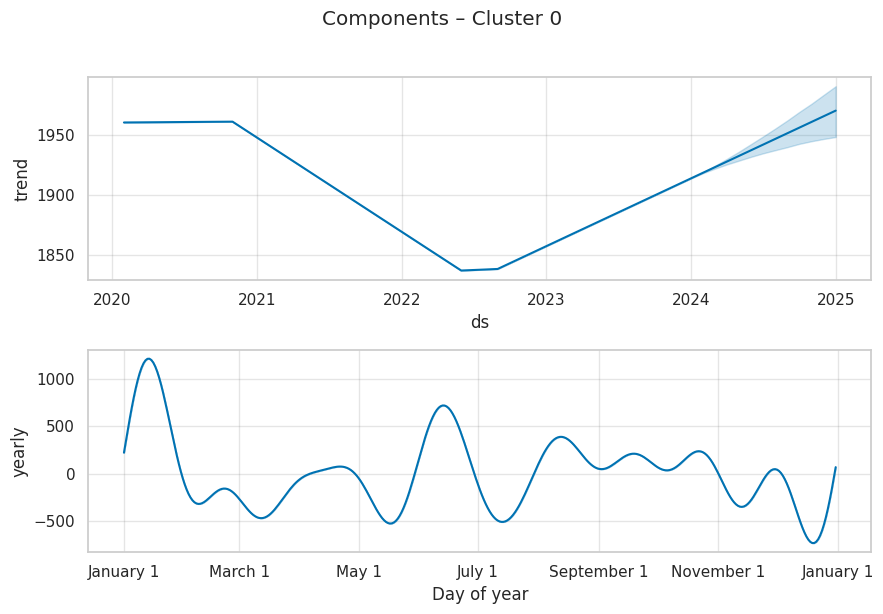

--------------------------------------------------
Forecasting for Cluster 1...
Forecast tail:


,ds,yhat,yhat_lower,yhat_upper
55,2024-08-31,6213.438846,6098.470236,6330.464377
56,2024-09-30,6100.777816,5987.246969,6221.432720
57,2024-10-31,6404.395069,6280.110362,6532.257381
58,2024-11-30,6380.342500,6270.628525,6504.503559
59,2024-12-31,6566.785709,6442.663135,6693.931864


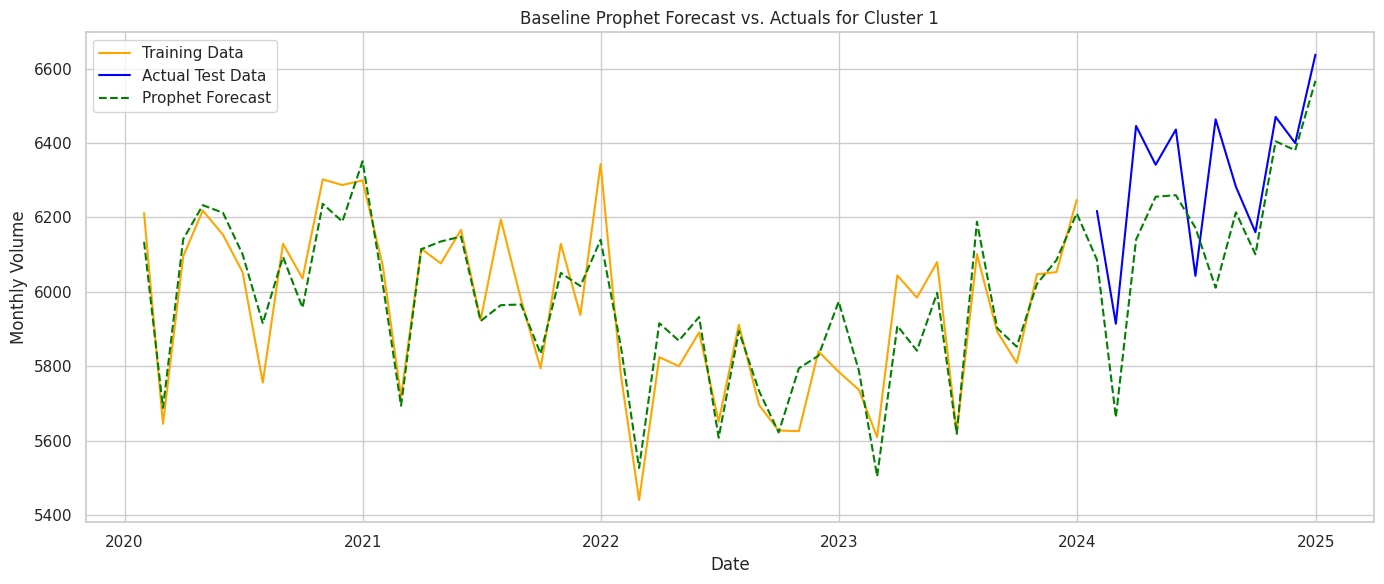

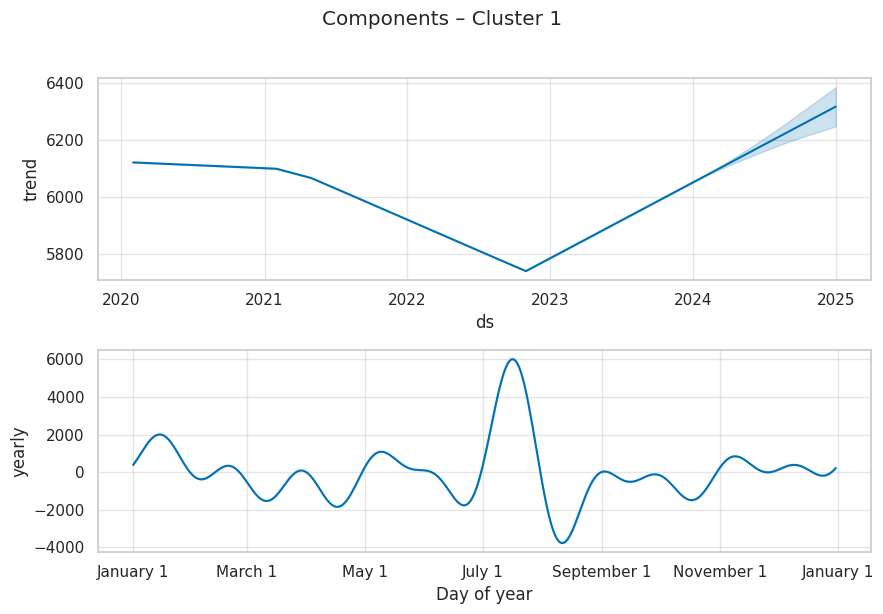

--------------------------------------------------
Forecasting for Cluster 2...
Forecast tail:


,ds,yhat,yhat_lower,yhat_upper
55,2024-08-31,3365.707994,3252.071592,3495.735298
56,2024-09-30,3435.988958,3316.096078,3549.655278
57,2024-10-31,3460.599710,3329.553571,3579.145785
58,2024-11-30,3120.469132,2994.388029,3236.954932
59,2024-12-31,1587.054181,1462.557307,1722.390040


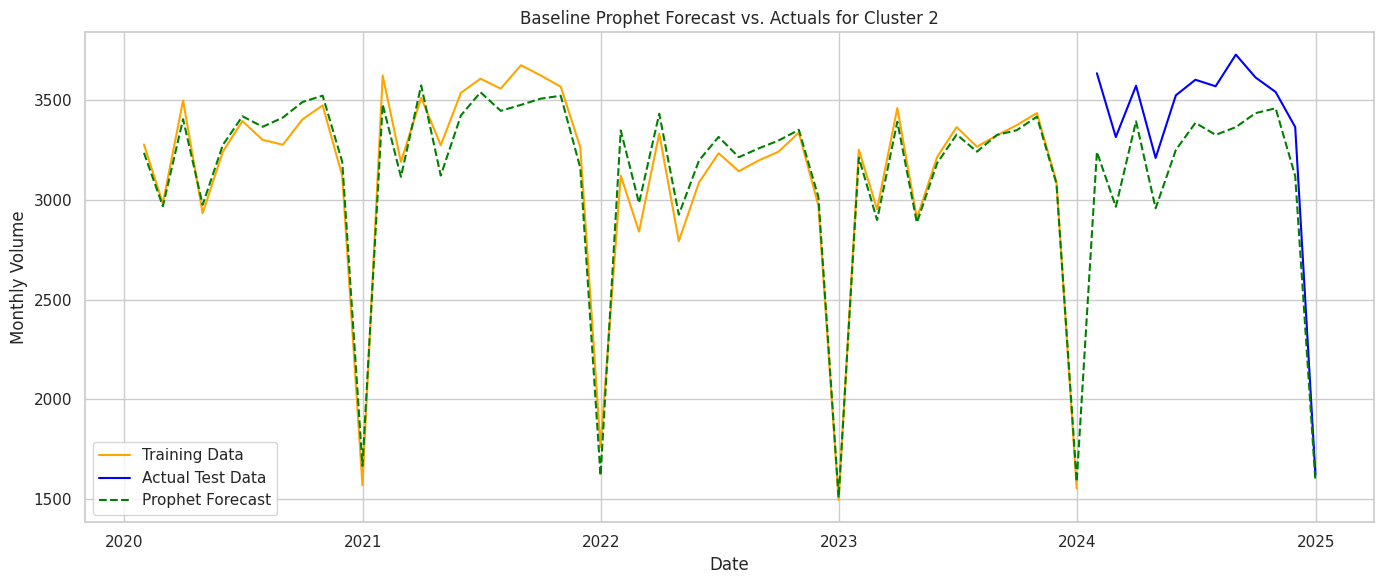

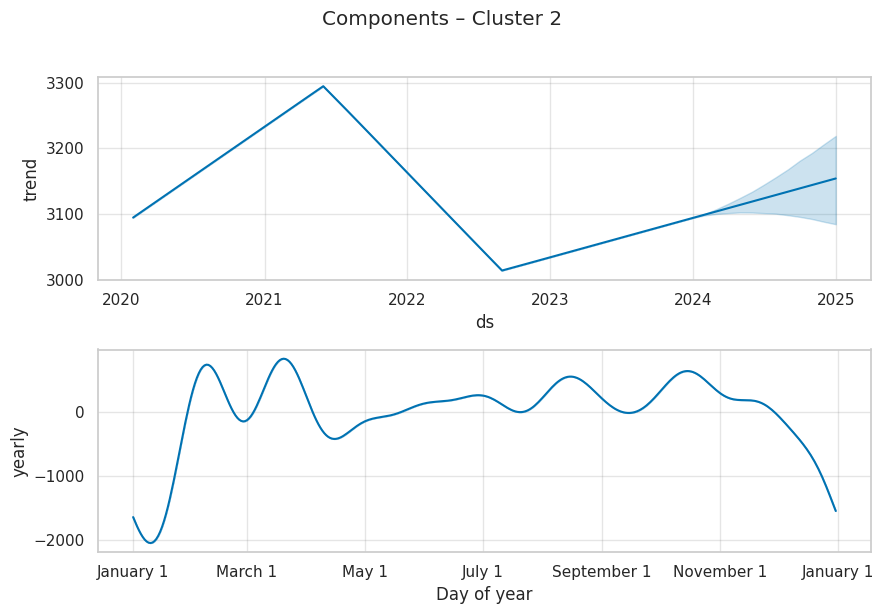

--------------------------------------------------
Cluster 0 → Prophet MAE=101.61, RMSE=114.17, MAPE=5.0%
Cluster 1 → Prophet MAE=151.35, RMSE=194.01, MAPE=2.4%
Cluster 2 → Prophet MAE=234.69, RMSE=256.46, MAPE=6.8%


,MAE,RMSE,MAPE
0,101.610474,114.168957,4.956670
1,151.353969,194.014639,2.398408
2,234.693590,256.464854,6.777419


DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/5wo6qic7.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/wm3cft2v.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=81860', 'data', 'file=/tmp/tmpbqdngb7u/5wo6qic7.json', 'init=/tmp/tmpbqdngb7u/wm3cft2v.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_modelecve512b/prophet_model-20250826191522.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:15:22 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing



Tuning Cluster 0...
  Using CV settings: initial=720 days, period=180 days, horizon=360 days


19:15:22 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
INFO:prophet:Making 2 forecasts with cutoffs between 2022-07-09 00:00:00 and 2023-01-05 00:00:00


...

INFO:prophet:n_changepoints greater than number of observations. Using 23.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/mx8uo78w.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/_1f3blys.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=25382', 'data', 'file=/tmp/tmpbqdngb7u/mx8uo78w.json', 'init=/tmp/tmpbqdngb7u/_1f3blys.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_model3mdk7bh6/prophet_model-20250826191912.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:19:12 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:19:37 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/dro8r6li.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/of3nw7y9.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:ru

  0%|          | 0/2 [00:00<?, ?it/s]

INFO:prophet:n_changepoints greater than number of observations. Using 23.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/omfd67cf.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/u4ucg43s.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=58788', 'data', 'file=/tmp/tmpbqdngb7u/omfd67cf.json', 'init=/tmp/tmpbqdngb7u/u4ucg43s.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_model3yzt66c_/prophet_model-20250826191959.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:19:59 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:20:19 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/aexh066v.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/6qttt8j_.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:ru

→ Best MAPE for Cluster 2: 10.10% | Params: {'changepoint_prior_scale': 0.5, 'seasonality_mode': 'multiplicative'}

Cluster 0 → Using params: {'changepoint_prior_scale': 0.1, 'seasonality_mode': 'additive'}


19:20:21 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


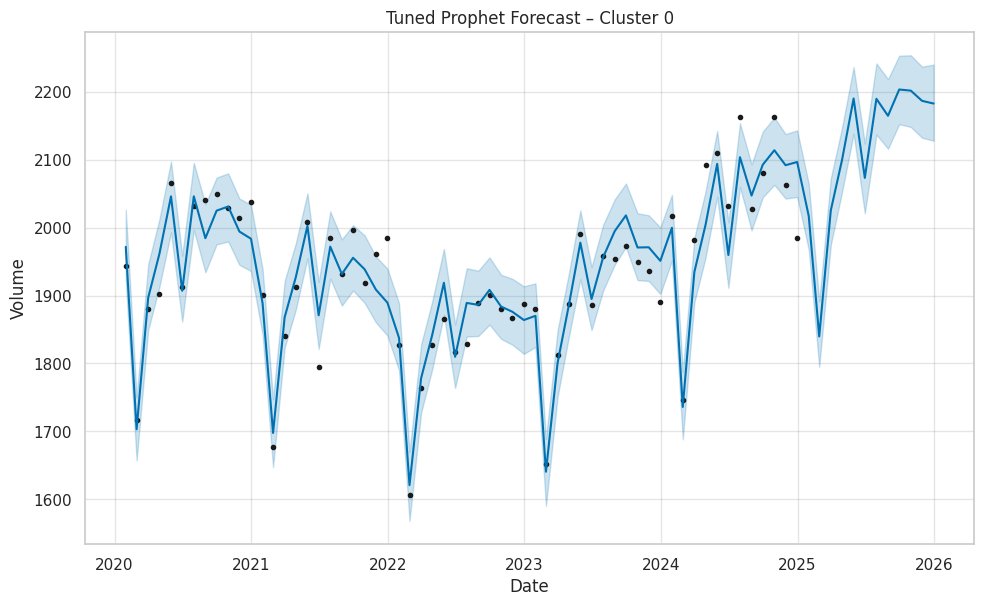

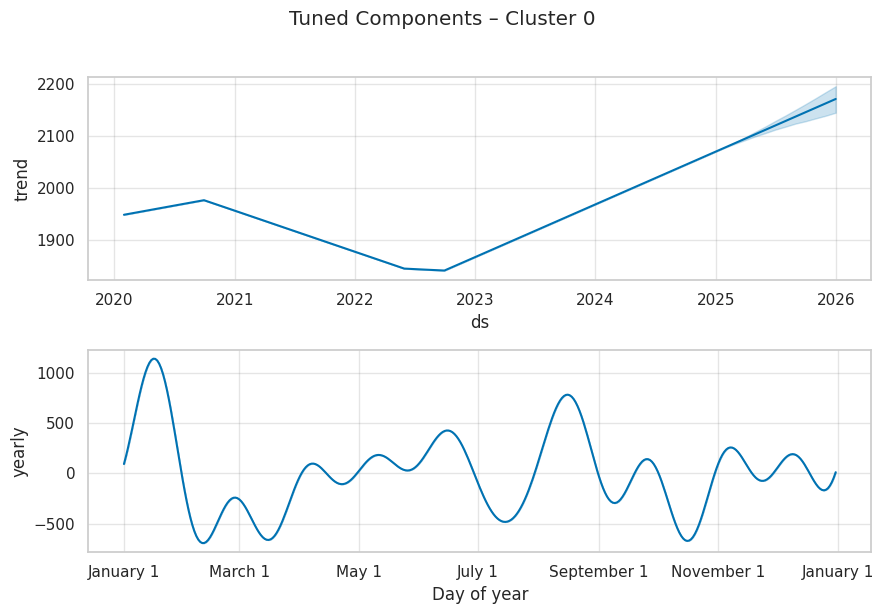

DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/dfsgl5rj.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/dxcq42fd.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=69520', 'data', 'file=/tmp/tmpbqdngb7u/dfsgl5rj.json', 'init=/tmp/tmpbqdngb7u/dxcq42fd.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_modelu02kgewh/prophet_model-20250826192022.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:20:22 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing



Cluster 1 → Using params: {'changepoint_prior_scale': 0.05, 'seasonality_mode': 'multiplicative'}


19:20:22 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


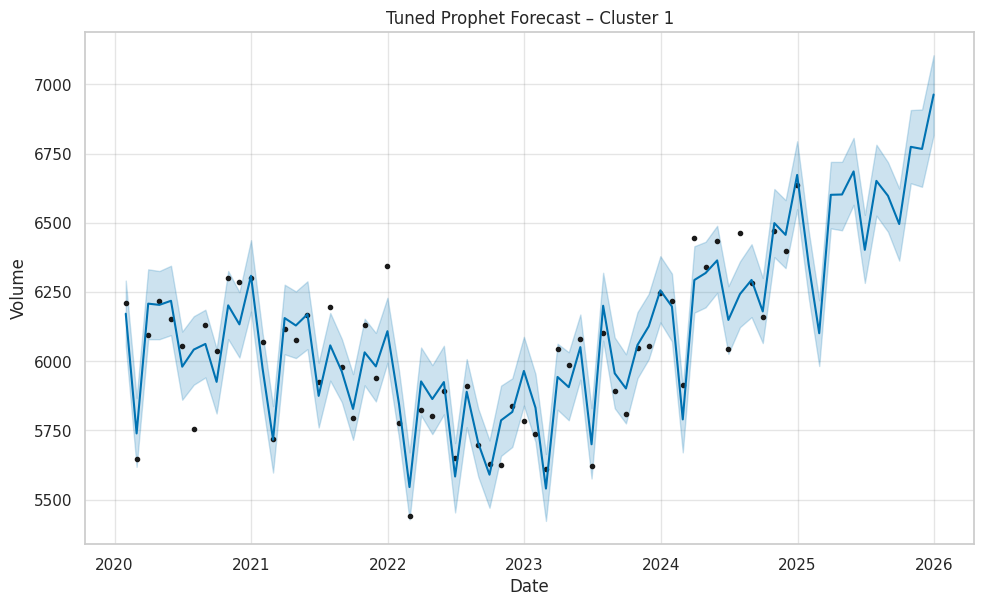

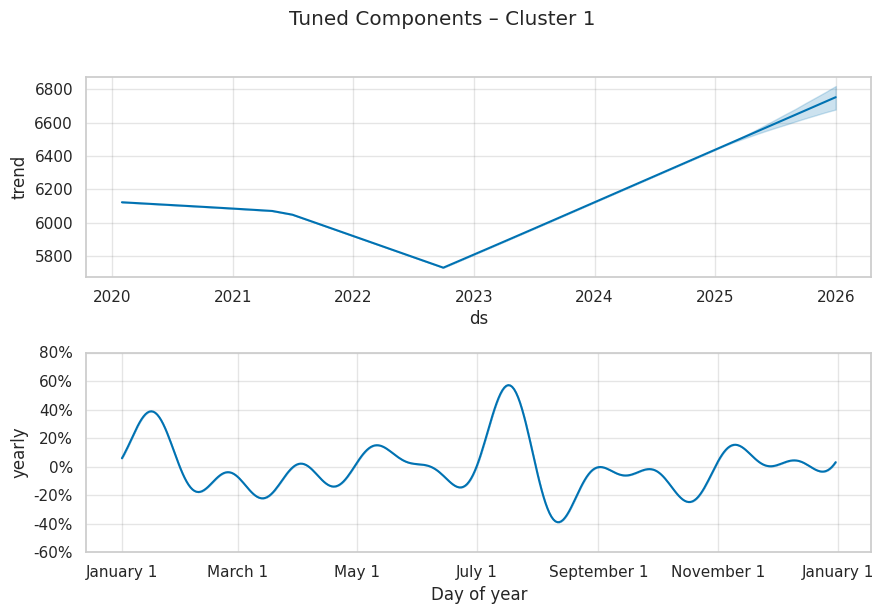

DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/irl22uo8.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpbqdngb7u/rq00_kow.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=85556', 'data', 'file=/tmp/tmpbqdngb7u/irl22uo8.json', 'init=/tmp/tmpbqdngb7u/rq00_kow.json', 'output', 'file=/tmp/tmpbqdngb7u/prophet_modelw2sh2org/prophet_model-20250826192024.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
19:20:24 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing



Cluster 2 → Using params: {'changepoint_prior_scale': 0.5, 'seasonality_mode': 'multiplicative'}


19:20:25 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


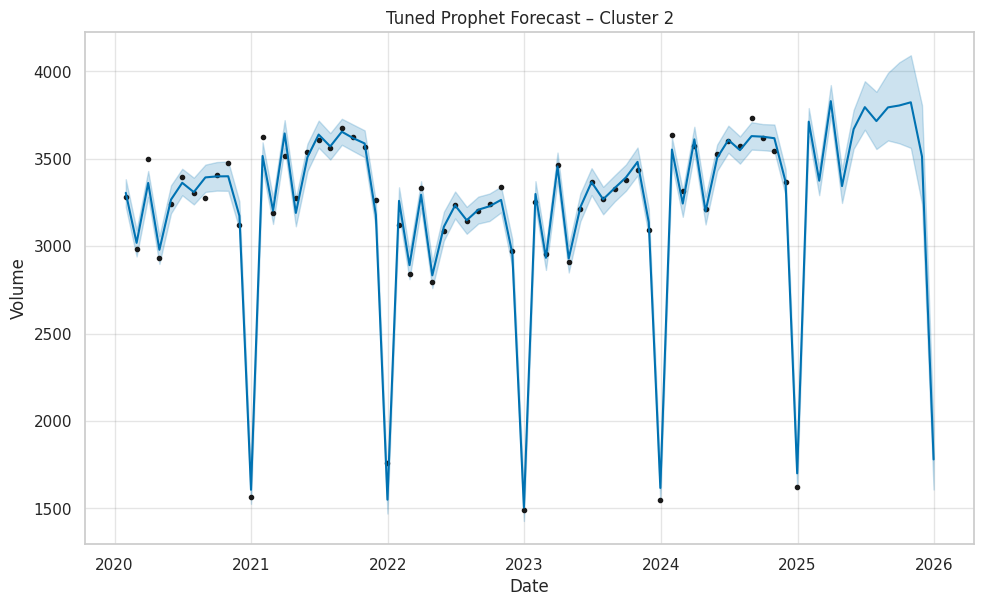

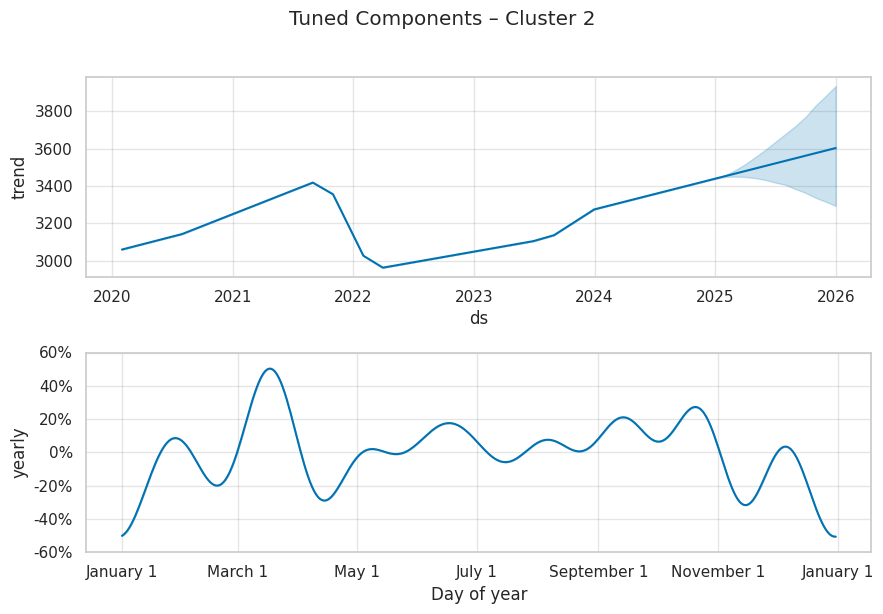


Evaluating Tuned Prophet Forecasts
Cluster 0: MAE = 44.20, RMSE = 54.37, MAPE = 2.16%
Cluster 1: MAE = 72.56, RMSE = 96.08, MAPE = 1.15%
Cluster 2: MAE = 43.32, RMSE = 55.61, MAPE = 1.44%


,MAE,RMSE,MAPE
0,44.195183,54.373559,2.155826
1,72.557435,96.077344,1.150696
2,43.316379,55.609371,1.442783


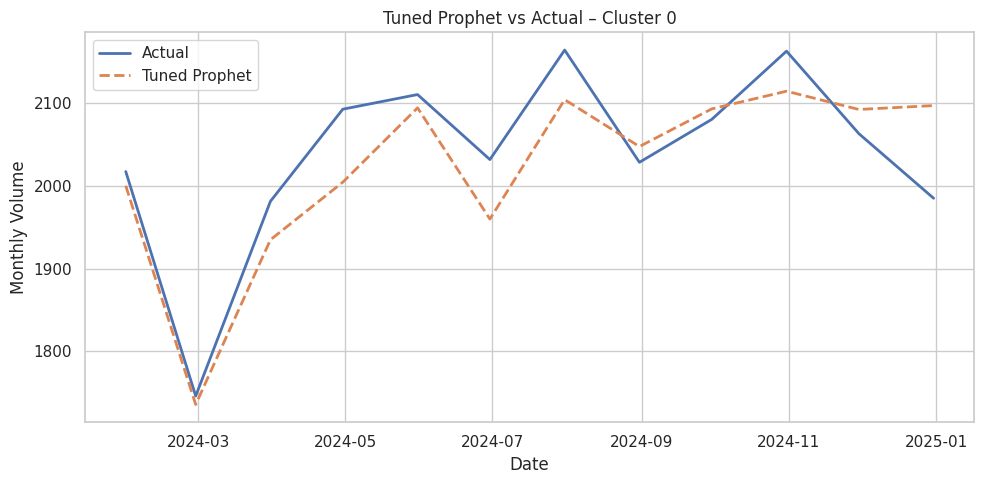

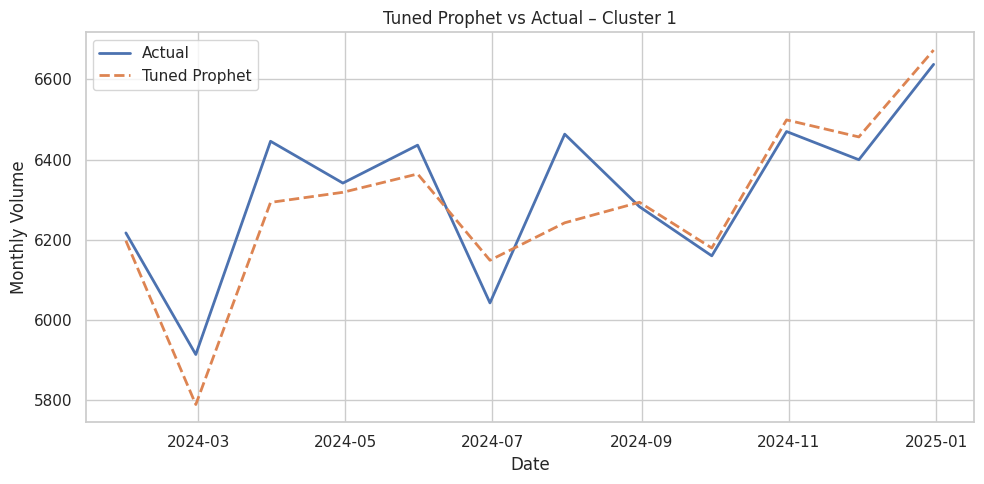

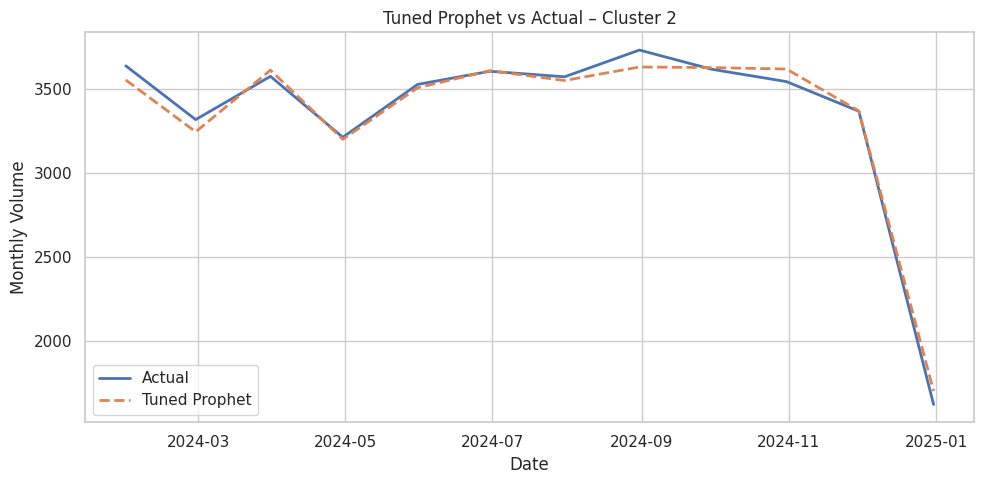

Comparison of Prophet vs SARIMAX:


,MAE_Prophet_Tuned,RMSE_Prophet_Tuned,MAPE_Prophet_Tuned,MAE_SARIMAX,RMSE_SARIMAX,MAPE_SARIMAX,Test_Mean,MAE_%
0,44.195183,54.373559,2.155826,198.759866,209.007379,9.652180,2038.196656,9.751751
1,72.557435,96.077344,1.150696,282.943217,290.813677,4.455842,6317.536002,4.478696
2,43.316379,55.609371,1.442783,150.970802,177.379352,4.337454,3359.369588,4.494022


In [43]:
# Run the main pipeline
if __name__ == "__main__":
    main_pipeline()